# Phase 22 — Multi-Domain Scale, Regional-Benefit & Resource Gap Analysis
### A diagnostic, inference-only gap analysis on the frozen Phase-21 reference

| Item | Value |
|---|---|
| Phase | 22 (Stage B, diagnostic) |
| Canonical folder | `notebooks/phasewise/phase_22_resource_gap/` |
| Reference model | frozen Phase-21 **Global MedFiLM** (unchanged, 3,523,001 params) |
| Checkpoint | `checkpoints/phase21_global_medfilm_fourdomain_seed42_clean_v3/best.pt` |
| Protocol | `reports/audits/phase22_diagnostic_protocol.json` (frozen before execution) |
| Reference binding | `reports/audits/phase22_phase21_reference_binding.json` (38/38 PASS) |
| Population | the **same 808 VAL cases** as Phase 21 (patient-disjoint) |
| New training | **NONE** — zero optimisers, zero backward passes, zero writes |
| Architecture change | **NONE** |
| Benefit predictor | **NONE trained** (labels are *contracted*, not used) |
| Cohort read | VAL only (plus TRAIN/VAL manifest metadata) |
| TEST | **CLOSED** — 0 image reads, 0 mask reads, 0 inference, 0 visualizations |
| Terminal state | `PHASE22_MULTIDOMAIN_SCALE_REGIONAL_RESOURCE_GAP_ANALYSIS_COMPLETE__PHASE23_ELIGIBLE_NOT_STARTED` |

**What Phase 22 is.** A *gap analysis*: it measures how large the headroom is along three
candidate axes — **input scale**, **regional refinement**, and **conditional compute** —
without proposing, training, or claiming any method. It exists to inform the Phase-24
design, not to pre-empt it.

**What Phase 22 is NOT.** It is **NOT** the RA-MedFiLM-Seg++ model. It contains **NO**
trained router, **NO** learned localizer, **NO** benefit predictor, **NO** architecture
search, **NO** compression/pruning/quantization/distillation, and **NO** Phase-23
literature audit. Phase 23 is **not started**.

**Interpretation guards (binding on every claim in this notebook).**

1. The **ORACLE regional arm uses ground-truth geometry**. It is an **upper bound**. It
   must never be presented as a deployable gain, and no method may be said to "achieve" it.
2. Where a paired CI overlaps zero, the arms are **not separable** and **no ordering** may
   be stated.
3. The reference is the **lightest of the six-model panel**, but ~31.6 G MACs per image is
   **not** a small absolute cost. "Lightest of the panel" must never be reported as "fit
   for constrained deployment."
4. No claim may be phrased as **"X caused +Y"**. Only *"the reference achieved X compared
   with baseline Y"* is permitted.

## 1. Environment and deterministic setup

In [1]:
import sys, json, hashlib, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path(r"D:/Softfors/jup")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image

AUD = ROOT / "reports/audits"
TAB = ROOT / "reports/tables"
FIG = ROOT / "reports/figures/phase22_resource_gap"

def load(name):
    p = AUD / name
    return json.loads(p.read_text(encoding="utf-8")) if p.exists() else {}

def sha(p):
    p = Path(p)
    return hashlib.sha256(p.read_bytes()).hexdigest() if p.exists() else None

def sty(df, uid, fmt=None, **kw):
    """Deterministic Styler (fixed uuid => SHA-stable notebook output)."""
    fmt = {**(fmt or {}), **kw}
    return df.style.format(fmt).set_uuid(uid)

def show(fname, width=900):
    """Display a required figure from the EXPLICIT figure manifest.

    The manifest (``reports/figures/phase22_resource_gap/phase22_figure_manifest.csv``)
    declares every required figure with ``figure_id, source_path, section, caption,
    semantic_role, expected_to_embed, source_sha256``. This helper is FAIL-CLOSED:
    if a required figure cannot be located, decoded, or PIL-verified it raises, so
    the notebook can never print "figure unavailable" and keep building while
    claiming the reviewer package is complete.

    The frozen on-disk names use the short ``p22_`` prefix while the notebook
    historically referred to them by their ``phase22_`` descriptive names; both
    forms resolve to the same manifest row.
    """
    want = fname
    if want.endswith(".png"):
        want = want[:-4]
    if want.startswith("phase22_"):
        want = "p22_" + want[len("phase22_"):]

    man = globals().get("FIG_MANIFEST")
    if man is None or not len(man):
        _m = FIG / "phase22_figure_manifest.csv"
        if not _m.exists():
            raise FileNotFoundError(
                "figure manifest missing; run "
                "src.analysis.phase22_figures.build_all() first: " + str(_m))
        man = pd.read_csv(_m)
        globals()["FIG_MANIFEST"] = man

    _row = man[man["figure_id"] == want]
    if not len(_row):
        raise KeyError(f"figure not declared in manifest: {want!r}")
    row = _row.iloc[0]
    if not bool(row.get("expected_to_embed", True)):
        print("figure declared not required for embedding:", want)
        return
    p = ROOT / str(row["source_path"]) if "source_path" in row.index and         str(row.get("source_path", "")) not in ("", "nan") else FIG / f"{want}.png"
    if not p.exists():
        p = ROOT / str(row.get("file", ""))
    if not p.exists():
        raise FileNotFoundError(f"required figure missing on disk: {p}")
    import io
    from PIL import Image as _PILImage
    raw = p.read_bytes()
    if not raw.startswith(b"\x89PNG\r\n\x1a\n"):
        raise ValueError(f"required figure is not a PNG: {p}")
    with _PILImage.open(io.BytesIO(raw)) as _im:
        _im.verify()
    with _PILImage.open(io.BytesIO(raw)) as _im:
        w, h = _im.size
    if w <= 0 or h <= 0:
        raise ValueError(f"required figure has degenerate dimensions: {p} {w}x{h}")
    _src = str(row.get("source_sha256", ""))
    if _src and _src != "nan":
        got = hashlib.sha256(raw).hexdigest()
        if got != _src:
            raise ValueError(
                f"required figure SHA mismatch for {want}: manifest={_src[:16]} "
                f"disk={got[:16]} — rebuild the figures before the notebook")
    # Downscale for embedding only when the payload is large; the ORIGINAL
    # source file is never modified.
    if len(raw) > 250_000:
        with _PILImage.open(io.BytesIO(raw)) as _im:
            _im = _im.convert("RGB")
            sw, sh = _im.size
            if sw > 1600:
                _im = _im.resize((1600, max(1, int(round(sh * 1600 / sw))))) 
            buf = io.BytesIO()
            _im.save(buf, format="PNG", optimize=True)
        raw = buf.getvalue()
    display(Image(data=raw, format="png", embed=True, width=min(width, w)))

def table(name):
    p = TAB / name
    return pd.read_csv(p) if p.exists() else pd.DataFrame()

print("numpy", np.__version__, "| pandas", pd.__version__)
_mf = FIG / "phase22_figure_manifest.csv"
FIG_MANIFEST = pd.read_csv(_mf) if _mf.exists() else pd.DataFrame()
if len(FIG_MANIFEST):
    print("figure manifest:", len(FIG_MANIFEST), "declared figures |",
          int(FIG_MANIFEST["expected_to_embed"].sum()), "required for embedding")
else:
    print("figure manifest NOT FOUND — run phase22_figures.build_all() first")

numpy 2.4.6 | pandas 3.0.5
figure manifest: 15 declared figures | 15 required for embedding


## 2. Governance: TEST lock and the frozen diagnostic protocol

In [2]:
from src.utils.test_lock import verify_test_lock
verify_test_lock(str(ROOT))

PROT = load("phase22_diagnostic_protocol.json")
EG = load("phase22_entry_gate.json")
RB = load("phase22_phase21_reference_binding.json")

display(sty(pd.DataFrame([
    {"item": "protocol id", "value": PROT.get("protocol_id")},
    {"item": "frozen before execution", "value": PROT.get("frozen_before_execution")},
    {"item": "protocol SHA-256", "value": (PROT.get("protocol_sha256") or "")[:32]},
    {"item": "entry-gate verdict", "value": EG.get("verdict")},
    {"item": "entry-gate checks", "value": f"{EG.get('n_passed')}/{EG.get('n_checks')}"},
    {"item": "reference binding verdict", "value": RB.get("verdict")},
    {"item": "reference binding checks", "value": f"{RB.get('n_passed')}/{RB.get('n_checks')}"},
    {"item": "TEST image reads", "value": PROT.get("test_reads", {}).get("test_image_reads", 0)},
    {"item": "TEST mask reads", "value": PROT.get("test_reads", {}).get("test_mask_reads", 0)},
    {"item": "TEST inference", "value": PROT.get("test_reads", {}).get("test_inference", 0)},
    {"item": "TEST visualizations", "value": PROT.get("test_reads", {}).get("test_visualization", 0)},
]), "p22_gov", value="{!s}"))

print("Required outputs declared in the frozen protocol:", len(PROT.get("required_outputs", [])))
print("TEST lock verified against manifests/test.csv sha256.")

,item,value
0,protocol id,phase22_diagnostic_protocol_v1
1,frozen before execution,None
2,protocol SHA-256,
3,entry-gate verdict,PHASE22_ENTRY_GATE_PASS
4,entry-gate checks,22/22
5,reference binding verdict,PHASE22_REFERENCE_BINDING_PASS
6,reference binding checks,38/38
7,TEST image reads,0
8,TEST mask reads,0
9,TEST inference,0


Required outputs declared in the frozen protocol: 29
TEST lock verified against manifests/test.csv sha256.


## 3. Reference binding — every Phase-22 identity anchored to the frozen Phase-21 run

Phase 22 may not invent a new reference. Every identity it depends on (experiment id,
checkpoint SHA, protocol SHA, task-id map, threshold, channel policy, population) is bound
to the frozen Phase-21 artifacts *fail-closed*: any mismatch aborts rather than warns.

In [3]:
rows = RB.get("checks", [])
df_checks = pd.DataFrame(rows)
keep = [c for c in ["check", "pass", "observed", "expected"] if c in df_checks.columns]
if len(df_checks):
    display(sty(df_checks[keep], "p22_bind"))
print("Verdict:", RB.get("verdict"), "|", RB.get("n_passed"), "/", RB.get("n_checks"))

b = RB.get("binding", {})
display(sty(pd.DataFrame([
    {"item": "phase-21 experiment", "value": b.get("phase21_experiment_id")},
    {"item": "architecture id", "value": b.get("phase21_architecture_id")},
    {"item": "checkpoint SHA-256", "value": (b.get("phase21_checkpoint_sha256") or "")[:32]},
    {"item": "Phase-20 protocol SHA", "value": (b.get("phase20_protocol_sha256") or "")[:16]},
    {"item": "Phase-22 protocol SHA", "value": (b.get("phase22_protocol_sha256") or "")[:32]},
    {"item": "persisted prediction counts", "value": json.dumps(b.get("persisted_prediction_counts"))},
    {"item": "Phase-21 reference macro Dice", "value": b.get("phase21_reference_macro_domain_dice")},
]), "p22_bind_sum", value="{!s}"))
print("Inference performed while binding:", not RB.get("no_inference_performed_here", True))

,check,pass,observed,expected
0,phase22_protocol_frozen,True,True,True
1,phase22_protocol_declared_before_outcomes,True,True,True
2,phase22_protocol_is_not_training_phase,True,False,False
3,phase21_freeze_verified,True,True,True
4,phase21_validation_problems_empty,True,[],[]
5,phase21_terminal_state,True,PHASE21_GLOBAL_MEDFILM_REFERENCE_COMPLETE__PHASE22_ELIGIBLE_NOT_STARTED,PHASE21_GLOBAL_MEDFILM_REFERENCE_COMPLETE__PHASE22_ELIGIBLE_NOT_STARTED
6,phase21_is_global_reference_only,True,True,True
7,phase21_is_not_final_ra_medfilm_seg_plus_plus,True,False,False
8,phase20_protocol_sha_matches_expected,True,b74f1f9f429adbce374f0306180943b9f373f872e1e69e115b7d17e81414283c,b74f1f9f429adbce374f0306180943b9f373f872e1e69e115b7d17e81414283c
9,phase20_protocol_sha_matches_freeze,True,b74f1f9f429adbce374f0306180943b9f373f872e1e69e115b7d17e81414283c,b74f1f9f429adbce374f0306180943b9f373f872e1e69e115b7d17e81414283c


Verdict: PHASE22_REFERENCE_BINDING_PASS | 38 / 38


,item,value
0,phase-21 experiment,phase21_global_medfilm_fourdomain_seed42_clean_v3
1,architecture id,global_medfilm_shared_residual_unet_film5_no_se_no_deep_supervision_v1
2,checkpoint SHA-256,286689fdd5c63ad75a383151d267af8b
3,Phase-20 protocol SHA,b74f1f9f429adbce
4,Phase-22 protocol SHA,9d620d6c85276e1a9a086ec60172cdef
5,persisted prediction counts,"{""BUSI"": 84, ""ISIC"": 357, ""KUB"": 280, ""KVASIR"": 87}"
6,Phase-21 reference macro Dice,0.8350794169575282


Inference performed while binding: False


## 4. Decision-rule audit — the float16 probability / uint8 prediction incompatibility

The persisted Phase-21 maps store a **float16** probability and a **uint8** prediction. A
float16 probability cannot reproduce the stored uint8 prediction exactly: pixels sitting at
*exactly* 0.5 are labelled both ways across the corpus. This section quantifies the
incompatibility and pins the single rule applied everywhere in Phase 22.

In [4]:
TA = load("phase22_threshold_rule_audit.json")
fnd = TA.get("finding", {})
dec = TA.get("decision", {})
cand = TA.get("candidate_rules", {})
ge = cand.get("ge_float32_prob_ge_0p5", {})
gt = cand.get("gt_float32_prob_gt_0p5", {})
display(sty(pd.DataFrame([
    {"item": "adopted rule", "value": dec.get("adopted_rule")},
    {"item": "exact-0.5 pixels", "value": fnd.get("pixels_exactly_float16_0p5")},
    {"item": "  of which labelled foreground", "value": fnd.get("of_which_labelled_foreground")},
    {"item": "  of which labelled background", "value": fnd.get("of_which_labelled_background")},
    {"item": "mixed labels present", "value": fnd.get("mixed_labels_present")},
    {"item": "maps with mixed tie labels", "value": fnd.get("maps_with_mixed_tie_labels")},
    {"item": ">= rule: mismatch pixels", "value": ge.get("mismatch_pixels")},
    {"item": ">= rule: mismatch maps", "value": ge.get("maps_with_any_mismatch")},
    {"item": ">= rule: matches frozen eval code", "value": ge.get("matches_frozen_evaluation_code")},
    {"item": ">  rule: mismatch pixels", "value": gt.get("mismatch_pixels")},
    {"item": ">  rule: mismatch maps", "value": gt.get("maps_with_any_mismatch")},
]), "p22_thr", value="{!s}"))
print("Root cause:", fnd.get("root_cause"))
print("Unexplained disagreements at other values:",
      fnd.get("unexplained_disagreements_at_other_values"))
print()
for r in dec.get("rationale", []):
    print(" -", r)
print()
print("The adopted rule is the SMALLER-RESIDUAL rule AND is the frozen evaluation rule; it")
print("is applied IDENTICALLY to the reference map and to every probe arm, so no arm is advantaged.")

,item,value
0,adopted rule,pred = (float32(prob) >= 0.5)
1,exact-0.5 pixels,3362
2,of which labelled foreground,2284
3,of which labelled background,1078
4,mixed labels present,True
5,maps with mixed tie labels,327
6,>= rule: mismatch pixels,1078
7,>= rule: mismatch maps,373
8,>= rule: matches frozen eval code,True
9,> rule: mismatch pixels,2284


Root cause: the canonical pass thresholded float32 sigmoid outputs and then persisted the probabilities as float16; the two sides of the boundary collapse onto the same stored value
Unexplained disagreements at other values: {}

 - it is the rule the frozen evaluation code actually uses
 - it leaves the smaller residual of the two candidates
 - it is applied IDENTICALLY to the canonical reference maps and to every Phase-22 diagnostic probe, so all comparisons are internally consistent

The adopted rule is the SMALLER-RESIDUAL rule AND is the frozen evaluation rule; it
is applied IDENTICALLY to the reference map and to every probe arm, so no arm is advantaged.


## 5. Global failure atlas (§10) — where the frozen reference fails

,item,value
0,population (VAL),808
1,pooled mean Dice,0.8387815425121063
2,median Dice,0.8900949538512055
3,p05 Dice,0.5149409807368478
4,mean IoU / precision / recall,0.7505972529213987 / 0.8498984245015596 / 0.8596991104701931
5,Dice < 0.5 / < 0.7,38 / 102
6,empty-case rows,0
7,total foreground pixel error,5144149


,category,n,pct
0,EMPTY_CASE_BOTH,0,0.000000
1,EMPTY_CASE_FALSE_POS,0,0.000000
2,EMPTY_CASE_MISSED,0,0.000000
3,OVER_SEGMENTATION,43,5.321800
4,UNDER_SEGMENTATION,32,3.960400
5,MIXED_BOUNDARY,25,3.094100
6,GOOD,708,87.623800


,dataset,n,mean_dice,median_dice,sd_dice,p05_dice,p25_dice,min_dice,mean_iou,mean_precision,mean_recall,n_empty_case,n_gt_empty,n_pred_empty
0,BUSI,84,0.858823,0.896882,0.096316,0.669372,0.814566,0.479650,0.763646,0.860091,0.880625,0,0,0
1,ISIC,357,0.897189,0.933652,0.118708,0.656250,0.884345,0.226542,0.829819,0.914264,0.906878,0,0,0
2,KUB,280,0.764058,0.832886,0.201380,0.315909,0.731473,0.000000,0.650358,0.760812,0.803676,0,0,0
3,KVASIR,87,0.820247,0.891895,0.213243,0.373719,0.805043,0.000000,0.735523,0.862652,0.826200,0,0,0
4,ALL,808,0.838782,0.890095,0.171936,0.514941,0.812036,0.000000,0.750597,0.849898,0.859699,0,0,0


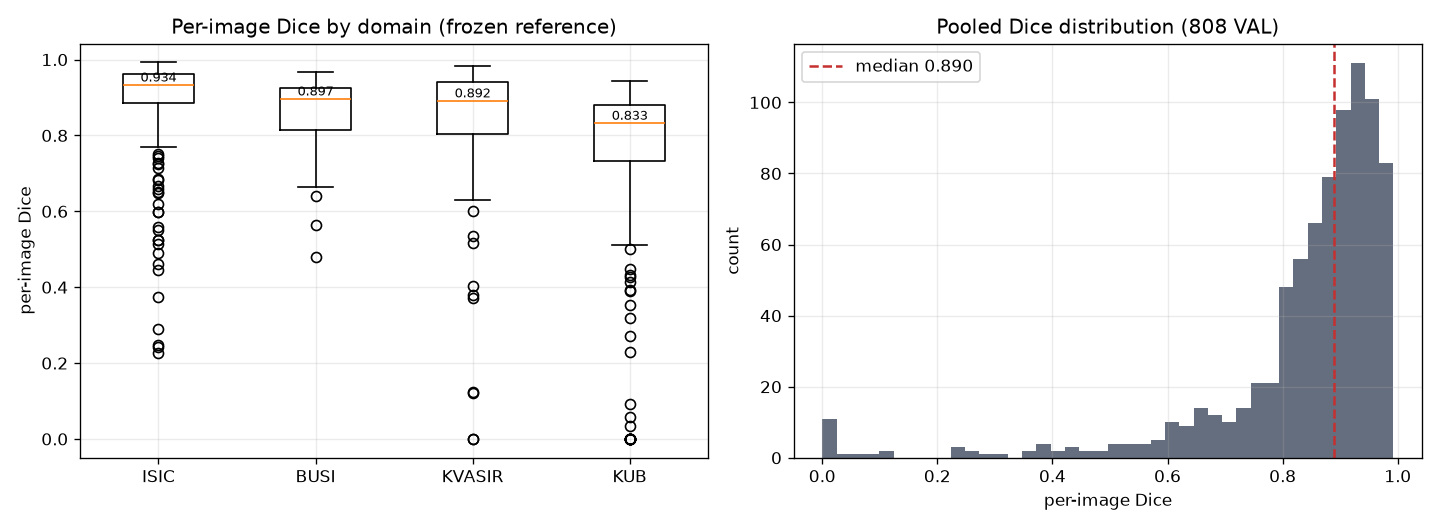

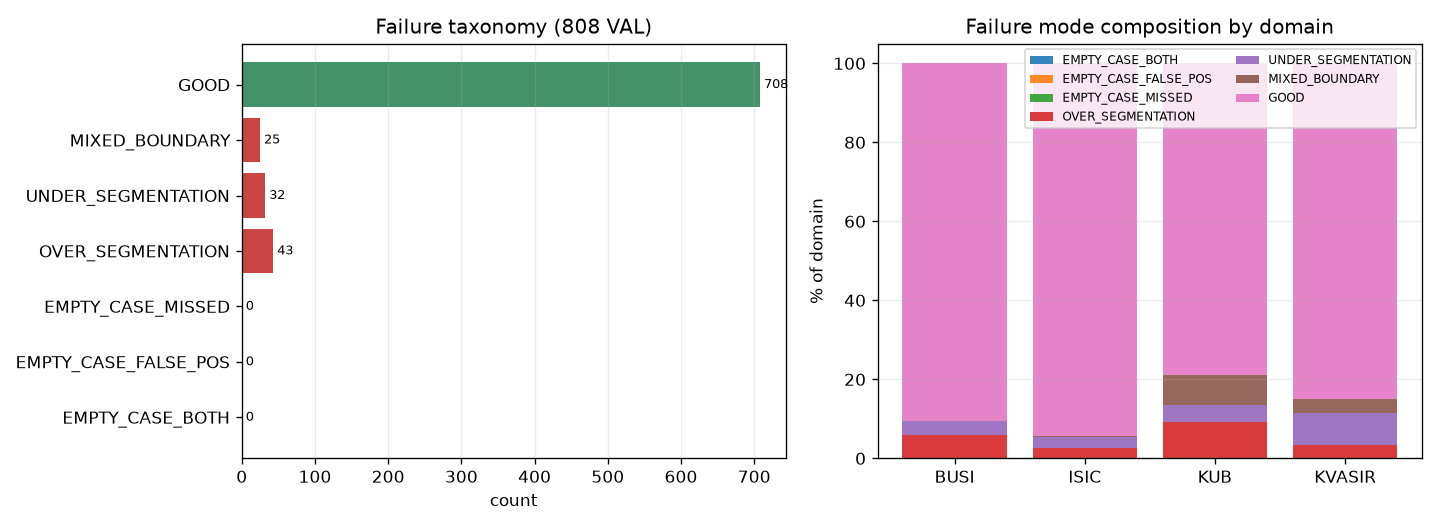

In [5]:
AT = load("phase22_global_failure_atlas.json")
ov = AT.get("overall", {})
display(sty(pd.DataFrame([
    {"item": "population (VAL)", "value": AT.get("n_samples")},
    {"item": "pooled mean Dice", "value": ov.get("mean_dice")},
    {"item": "median Dice", "value": ov.get("median_dice")},
    {"item": "p05 Dice", "value": ov.get("p05_dice")},
    {"item": "mean IoU / precision / recall",
     "value": f"{ov.get('mean_iou')} / {ov.get('mean_precision')} / {ov.get('mean_recall')}"},
    {"item": "Dice < 0.5 / < 0.7", "value": f"{ov.get('n_dice_below_0p5')} / {ov.get('n_dice_below_0p7')}"},
    {"item": "empty-case rows", "value": ov.get("n_empty_case")},
    {"item": "total foreground pixel error", "value": ov.get("total_foreground_pixel_error")},
]), "p22_atlas", value="{!s}"))

tc = AT.get("taxonomy_counts", {})
tp = AT.get("taxonomy_pct", {})
if tc:
    display(sty(pd.DataFrame([
        {"category": k, "n": v, "pct": tp.get(k)} for k, v in tc.items()]), "p22_atlas_taxo"))

fbd = table("phase22_failure_by_domain.csv")
if len(fbd):
    display(sty(fbd, "p22_atlas_dom"))
show("phase22_atlas_dice_distribution.png")
show("phase22_atlas_taxonomy.png")

## 6. Worst cases per domain (§10)

The taxonomy thresholds were **declared prospectively** in the frozen protocol and were
**not** used to select any case for intervention. They are descriptive only.

,dataset,rank_within_domain,sample_id,dice,iou,precision,recall,failure_mode,gt_foreground_pixels,pred_foreground_pixels,empty_case
0,ISIC,1,21c6342179f5a1bed9699cdb311717f1,0.226542,0.127740,0.811785,0.131639,UNDER_SEGMENTATION,143476,23266,both_nonempty
1,ISIC,2,97b46a68b6b195c6107d5df017e0d4e0,0.243434,0.138585,0.379697,0.179144,MIXED_BOUNDARY,17204,8117,both_nonempty
2,ISIC,3,f949cba8c894be5108592652ec7b1b6b,0.248310,0.141755,0.141755,1.000000,OVER_SEGMENTATION,4316,30447,both_nonempty
3,ISIC,4,4a861436fef3ba977fbcfb327e5922be,0.290396,0.169861,0.169861,1.000000,OVER_SEGMENTATION,31901,187806,both_nonempty
4,ISIC,5,6a44dbce48a66890f33d3483fe67f72e,0.374772,0.230597,1.000000,0.230597,UNDER_SEGMENTATION,14276,3292,both_nonempty
5,ISIC,6,7ab7c926d3bc315db15eafb7b623ae17,0.444141,0.285464,1.000000,0.285464,UNDER_SEGMENTATION,30785,8788,both_nonempty
6,ISIC,7,bb2b1c8a2c4aeb55ac0777082e654922,0.462056,0.300437,0.333179,0.753528,GOOD,17150,38787,both_nonempty
7,ISIC,8,f23c7cb165e42c3bda211f0be9fa316d,0.489869,0.324388,0.324388,1.000000,OVER_SEGMENTATION,4388,13527,both_nonempty
8,ISIC,9,720b5644c6fde18510b760117d1a49f1,0.513503,0.345445,0.406092,0.698169,GOOD,11248,19338,both_nonempty
9,ISIC,10,2a2da2e7af899f89878ae63813304dbf,0.523666,0.354707,0.996110,0.355199,UNDER_SEGMENTATION,43981,15683,both_nonempty


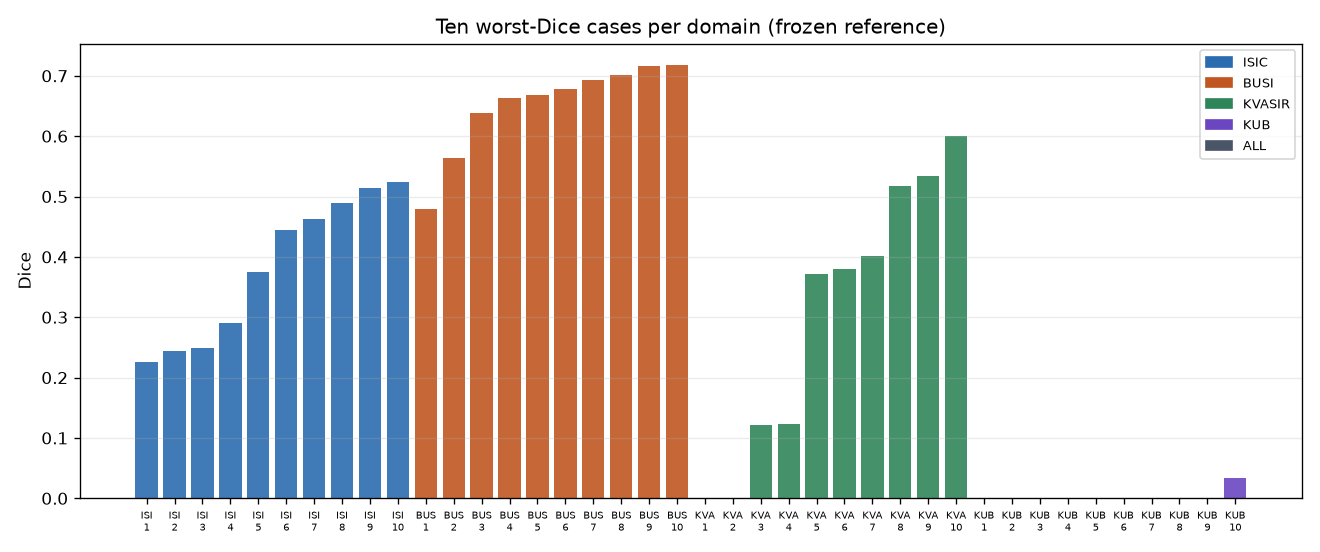

In [6]:
worst = table("phase22_worst_cases_per_domain.csv")
if len(worst):
    display(sty(worst.head(24), "p22_worst"))
show("phase22_atlas_worst_cases.png")

## 7. Scale sensitivity (§11 / §13) — 256 / 512 / 768 / 1024

Every probe re-runs the **same frozen checkpoint** at a different input resolution and is
scored in **NATIVE image space**, so a resolution change cannot be mistaken for a
segmentation change. 512 is the canonical reference and is read from the persisted Phase-21
probability maps (never re-inferred).

> **Required wording (B5).** For the frozen checkpoint trained at 512, 512 had the highest
> observed performance among the tested diagnostic resolutions (256/512/768/1024); all tested
> off-canonical sizes were worse. **This does not establish a globally optimal inference
> resolution.**

,probe_size,is_canonical_reference,n,macro_domain_dice_native,macro_domain_dice_delta_vs_512,delta_ci_low,delta_ci_high,delta_p_value,delta_separable_from_512,dice_ISIC,dice_BUSI,dice_KVASIR,dice_KUB
0,256,False,808,0.688499,-0.138240,-0.155253,-0.122172,0.000000,True,0.807881,0.653266,0.720408,0.572440
1,512,True,808,0.835343,0.000000,0.000000,0.000000,1.000000,False,0.897182,0.859187,0.820323,0.764682
2,768,False,808,0.776819,-0.036888,-0.044632,-0.029160,0.000000,True,0.882294,0.742876,0.747312,0.734794
3,1024,False,808,0.682561,-0.100413,-0.110645,-0.090445,0.000000,True,0.859924,0.548215,0.655032,0.667071


,probe_size,dataset,n,mean_dice,mean_recall,mean_precision
0,256,BUSI,84,0.653266,0.687913,0.705665
1,256,ISIC,357,0.807881,0.845441,0.862073
2,256,KUB,280,0.572440,0.559768,0.774558
3,256,KVASIR,87,0.720408,0.811056,0.717303
4,512,BUSI,84,0.859187,0.881004,0.860450
5,512,ISIC,357,0.897182,0.906909,0.914213
6,512,KUB,280,0.764682,0.800719,0.764172
7,512,KVASIR,87,0.820323,0.826363,0.862642
8,768,BUSI,84,0.742876,0.837435,0.716650
9,768,ISIC,357,0.882294,0.909557,0.884116


  size 256: macro Dice 0.6884987673610603 delta -0.13823991783628448 CI [-0.1552532908820662, -0.12217223483435337] separable=True
  size 512: macro Dice 0.8353433576469 delta 0.0 CI [0.0, 0.0] separable=False
  size 768: macro Dice 0.776819081711754 delta -0.03688789010381927 CI [-0.04463243450248566, -0.02915998185469751] separable=True
  size 1024: macro Dice 0.6825608407149975 delta -0.10041294963314609 CI [-0.11064502494972948, -0.09044540222448447] separable=True

Scale probes quantify sensitivity to input resolution for a model trained at 512. They do NOT establish an optimal resolution and are NOT a resolution search.


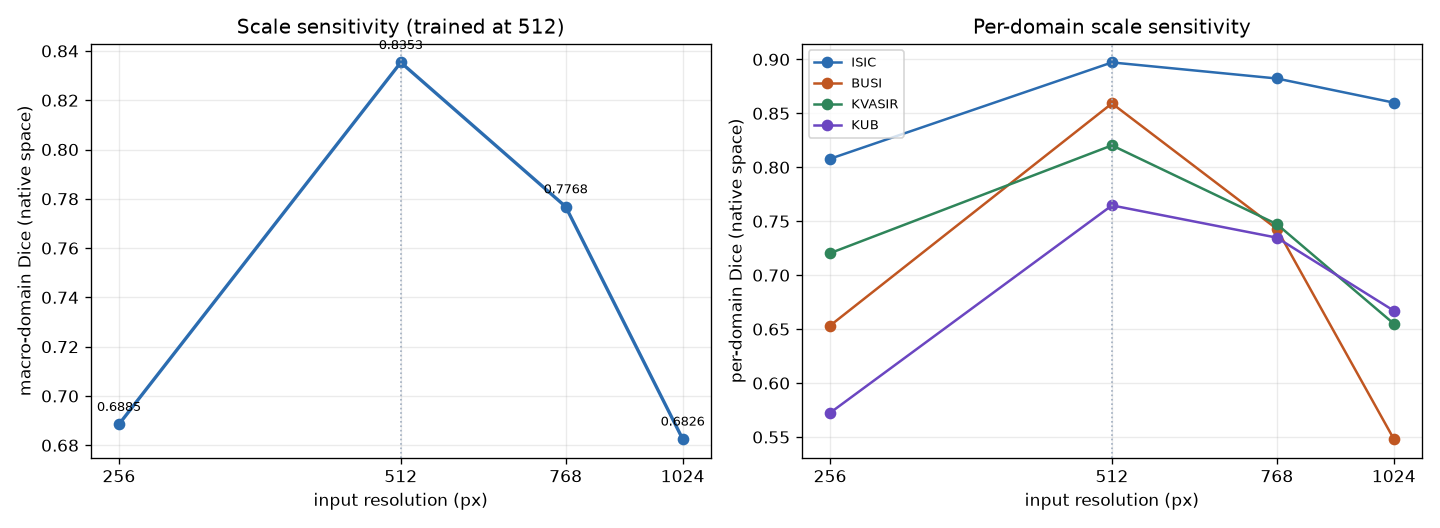

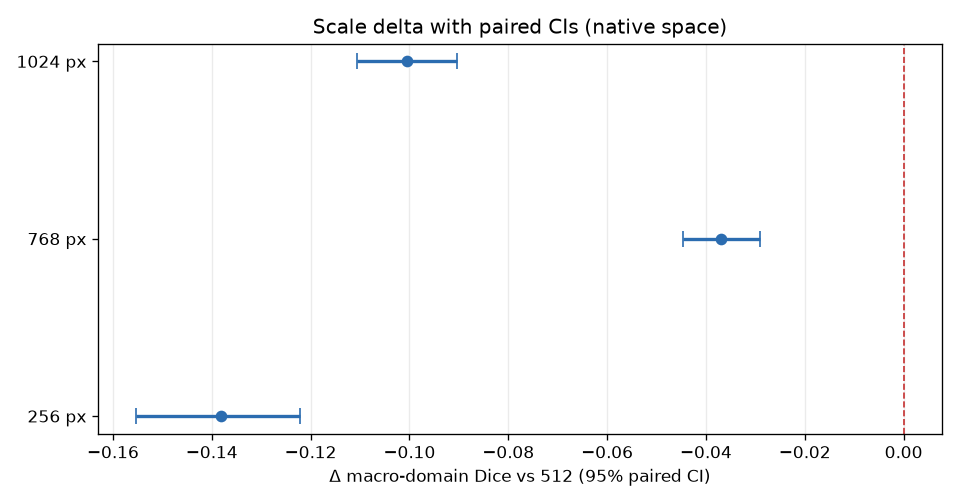

In [7]:
SS = load("phase22_scale_sensitivity.json")
sf = table("phase22_scale_sensitivity.csv")
if len(sf):
    display(sty(sf, "p22_scale"))
sfb = table("phase22_scale_sensitivity_by_domain.csv")
if len(sfb):
    display(sty(sfb, "p22_scale_dom"))

for r in SS.get("summary", []):
    print(f"  size {r.get('probe_size')}: macro Dice {r.get('macro_domain_dice_native')} "
          f"delta {r.get('macro_domain_dice_delta_vs_512')} "
          f"CI [{r.get('delta_ci_low')}, {r.get('delta_ci_high')}] "
          f"separable={r.get('delta_separable_from_512')}")
print()
print(SS.get("interpretation_guard"))
show("phase22_scale_curve.png")
show("phase22_scale_delta_ci.png")

## 8. Scale-probe fidelity gates (§11)

A scale probe is only meaningful if the probing code path is faithful to the canonical one.
Three gates are declared: (A) pipeline fidelity at 512 vs the canonical probability map in
the **shared 512 canvas**, (B) probability agreement, (C) agreement against the stored
prediction (**reported, not gated**, because of the float16 incompatibility in §4).

In [8]:
SF = load("phase22_scale_probe_fidelity.json")
gA = SF.get("gate_A_pipeline_fidelity", {})
gB = SF.get("gate_B_probability_map_agreement", {})
gC = SF.get("gate_C_disagreement_with_stored_pred", {})
display(sty(pd.DataFrame([
    {"item": "verdict", "value": SF.get("verdict")},
    {"item": "gate A (pipeline fidelity @512)", "value": gA.get("verdict")},
    {"item": "gate A disagreeing pixels", "value": gA.get("total_disagreeing_pixels")},
    {"item": "gate A all within boundary band", "value": gA.get("all_disagreements_within_boundary_band")},
    {"item": "gate A boundary tolerance", "value": gA.get("boundary_tolerance")},
    {"item": "gate B max |dp| (square)", "value": gB.get("max_abs_probability_difference_square")},
    {"item": "gate B verdict", "value": gB.get("verdict")},
    {"item": "gate C verdict (reported only)", "value": gC.get("verdict")},
]), "p22_fid", value="{!s}"))
print(gA.get("note"))
print()
print("Dice by decision source:", json.dumps(SF.get("dice_by_decision_source")))
print()
print("Gate A compares in the SHARED 512 square canvas. Comparing after unmap+re-map would")
print("insert two extra bilinear resamples per side and manufacture spurious disagreements.")

,item,value
0,verdict,PHASE22_SCALE_PROBE_FIDELITY_PASS
1,gate A (pipeline fidelity @512),PASS
2,gate A disagreeing pixels,2884
3,gate A all within boundary band,True
4,gate A boundary tolerance,0.02
5,gate B max |dp| (square),0.009233653545379639
6,gate B verdict,REVIEW
7,gate C verdict (reported only),REPORTED_NOT_GATED


A residual disagreement that is confined to pixels whose probability lies within 0.02 of the 0.5 threshold is float16 storage quantisation, not a pipeline divergence. Sizes are recorded so the magnitude is always visible.

Dice by decision source: {"probe_reinference_canonical_rule_native": 0.8390402334224809, "canonical_stored_pred_native": 0.8384789752954946, "canonical_stored_pred_in_512_square_space": 0.8387815425121063, "note": "Dice is insensitive to the float16 tie artefact at this scale; all three agree to ~1e-4."}

Gate A compares in the SHARED 512 square canvas. Comparing after unmap+re-map would
insert two extra bilinear resamples per side and manufacture spurious disagreements.


## 9. Regional intervention (§12 / §13) — ORACLE and PREDICTION-DERIVED

Both arms answer the **same** counterfactual: *if a region of interest were cropped,
resampled to 512 with the frozen contract, re-run through the same frozen checkpoint, and
re-projected into the full-field map, what would change?* Only the **source of the ROI**
differs. The ROI rule (tight bbox → centre-preserving 1.5× expansion → clip → square-pad →
resize → paste over the ROI footprint) is **frozen in the protocol** and identical for both.

,item,value
0,region fidelity max |dp| (square),0.009233653545379639
1,region fidelity thresholded px,2884
2,ROI margin,0.25
3,expanded extent factor,1.5
4,re-centred after clip,False
5,decision rule,"pred = (float32(prob) >= 0.5), applied to every arm"


[oracle] n_ok=808 n_no_roi=0 mean_delta(exec)=-0.04247786113739191 ITT=-0.04247786113739191
[predicted] n_ok=808 n_no_roi=0 mean_delta(exec)=-0.060217639536867054 ITT=-0.060217639536867054

The ORACLE variant is an upper bound that uses ground-truth geometry. It must NEVER be presented as a deployable gain, and no claim may be made that a regional mechanism 'achieves' or 'would achieve' it. The PREDICTED variant is the deployable-shaped diagnostic, but it is still an oracle-FREE offline estimate: no benefit predictor, router, or threshold policy was trained.


,dataset,n,n_oracle_ok,mean_global_dice,mean_oracle_dice,mean_oracle_delta_dice,mean_oracle_delta_dice_intent_to_treat,n_oracle_improved,n_oracle_worsened,mean_predicted_delta_dice,n_no_predicted_roi,mean_roi_area_fraction,mean_effective_magnification
0,ISIC,357,357,0.897182,0.871861,-0.025321,-0.025321,112,244,-0.030623,0,0.512275,0.560103
1,BUSI,84,84,0.859187,0.765810,-0.093377,-0.093377,16,68,-0.106559,0,0.319538,3.009791
2,KVASIR,87,87,0.820323,0.769551,-0.050773,-0.050773,24,63,-0.058724,0,0.530416,1.481115
3,KUB,280,280,0.764682,0.718176,-0.046506,-0.046506,119,161,-0.084512,0,0.505242,6.561400


,sample_id,dataset,task_id,native_h,native_w,gt_foreground_pixels,global_dice,global_iou,global_precision,global_recall,global_empty_case,gt_empty,global_pred_foreground_pixels,oracle_status,oracle_roi_side,oracle_roi_area_fraction,oracle_effective_magnification,oracle_roi_h,oracle_roi_w,oracle_clipped,oracle_dice,oracle_iou,oracle_precision,oracle_recall,oracle_delta_dice,oracle_delta_iou,oracle_delta_precision,oracle_delta_recall,oracle_fused_foreground_pixels,oracle_gain_pixels_outside_roi,predicted_status,predicted_roi_side,predicted_roi_area_fraction,predicted_effective_magnification,predicted_roi_h,predicted_roi_w,predicted_clipped,predicted_dice,predicted_iou,predicted_precision,predicted_recall,predicted_delta_dice,predicted_delta_iou,predicted_delta_precision,predicted_delta_recall,predicted_fused_foreground_pixels,predicted_gain_pixels_outside_roi
0,07451d37507d75a0456b73bc793517cc,BUSI,1,321,430,6853,0.911542,0.837462,0.862199,0.966876,both_nonempty,False,7685,OK,211,0.322546,2.426540,211,211,False,0.910725,0.836084,0.865536,0.960893,-0.000817,-0.001378,0.003337,-0.005983,7608,0,OK,214,0.331783,2.392523,214,214,False,0.912247,0.838652,0.870083,0.958704,0.000704,0.001190,0.007884,-0.008172,7551,0
1,0948733b6a18bf22439633947a5ee5ca,BUSI,1,376,363,3359,0.776741,0.634977,0.654820,0.954451,both_nonempty,False,4896,OK,161,0.189914,3.180124,161,161,False,0.582418,0.410853,0.519487,0.662697,-0.194324,-0.224125,-0.135334,-0.291753,4285,0,OK,181,0.240028,2.828729,181,181,False,0.619256,0.448494,0.523320,0.758261,-0.157485,-0.186483,-0.131500,-0.196189,4867,0
2,15389cbf2bdf0c79ba7a2646c704cbc2,BUSI,1,297,433,2001,0.903534,0.824042,0.865112,0.945527,both_nonempty,False,2187,OK,95,0.070178,5.389474,95,95,False,0.670758,0.504616,0.635510,0.710145,-0.232776,-0.319425,-0.229602,-0.235382,2236,0,OK,102,0.080901,5.019608,102,102,False,0.679840,0.514968,0.642222,0.722139,-0.223694,-0.309074,-0.222890,-0.223388,2250,0
3,1599bde0882e51e75ab5e22566586f2c,BUSI,1,300,503,8107,0.947781,0.900745,0.940812,0.954854,both_nonempty,False,8228,OK,218,0.314937,2.348624,218,218,False,0.868746,0.767949,0.964474,0.790305,-0.079035,-0.132796,0.023662,-0.164549,6643,0,OK,230,0.350563,2.226087,230,230,False,0.892113,0.805238,0.968777,0.826693,-0.055668,-0.095506,0.027965,-0.128161,6918,0
4,1601d2e98062d7667e5d37954d6607e4,BUSI,1,436,548,2975,0.879095,0.784273,0.869980,0.888403,both_nonempty,False,3038,OK,139,0.080865,3.683453,139,139,False,0.870189,0.770207,0.907333,0.835966,-0.008906,-0.014066,0.037353,-0.052437,2741,0,OK,126,0.066447,4.063492,126,126,False,0.840811,0.725344,0.800791,0.885042,-0.038284,-0.058929,-0.069189,-0.003361,3288,0
5,1c782ff218951681fef82b21a5482c66,BUSI,1,516,564,22501,0.922891,0.856823,0.965939,0.883516,both_nonempty,False,20581,OK,420,0.606136,1.219048,420,420,False,0.917495,0.847566,0.955751,0.882183,-0.005396,-0.009257,-0.010188,-0.001333,20769,0,OK,444,0.677387,1.153153,444,444,False,0.928207,0.866032,0.960411,0.898093,0.005316,0.009210,-0.005529,0.014577,21041,0
6,20637be7daca9bf96dd167b026f25819,BUSI,1,304,388,9043,0.925496,0.861325,0.962167,0.891518,both_nonempty,False,8379,OK,204,0.352821,2.509804,204,204,False,0.878421,0.783200,0.960373,0.809355,-0.047076,-0.078125,-0.001795,-0.082163,7621,0,OK,173,0.253739,2.959538,173,173,False,0.858846,0.752611,0.954189,0.780825,-0.066651,-0.108713,-0.007978,-0.110693,7400,0
7,22cc4cf93830dc2004ab106b6f165550,BUSI,1,288,315,18002,0.931041,0.870979,0.927984,0.934118,both_nonempty,False,18121,OK,285,0.895337,1.796491,285,285,True,0.922248,0.855714,0.917808,0.926730,-0.008793,-0.015265,-0.010176,-0.007388,18177,0,OK,288,0.914286,1.777778,288,288,True,0.923849,0.858475,0.922085,0.925619,-0.007192,-0.012504,-0.005899,-0.008499,18071,0
8,26d85d872ef1c5f8529766ddb889b4c2,BUSI,1,347,483,29222,0.941338,0.889178,0.923741,0.959619,both_nonempty,False,30357,OK,347,0.718426,1.475504,347,347,True,0.900137,0.818408,0.877633,0.923825,-0.041202,-0.070770,-0.046108,-0.035795,30760,0,OK,347,0.718426,1

phase22_regional_intervention_per_image.csv: 808 rows | 808 with oracle_status=OK


,sample_id,dataset,gt_bbox_h,gt_bbox_w,gt_bbox_area,expanded_h_requested,expanded_w_requested,expansion_factor_h,expansion_factor_w,clipped,roi_side,roi_area_fraction,effective_magnification,square_pad_shift_y,square_pad_shift_x,centre_preserved,mask_bbox_fraction_of_image
0,07451d37507d75a0456b73bc793517cc,BUSI,86,141,12126,130,211,1.511628,1.496454,False,211,0.322546,2.426540,14,0,False,0.087850
1,0948733b6a18bf22439633947a5ee5ca,BUSI,42,107,4494,62,161,1.476190,1.504673,False,161,0.189914,3.180124,0,0,True,0.032926
2,15389cbf2bdf0c79ba7a2646c704cbc2,BUSI,44,63,2772,66,95,1.500000,1.507937,False,95,0.070178,5.389474,0,0,True,0.021555
3,1599bde0882e51e75ab5e22566586f2c,BUSI,94,146,13724,142,218,1.510638,1.493151,False,218,0.314937,2.348624,0,0,True,0.090948
4,1601d2e98062d7667e5d37954d6607e4,BUSI,54,93,5022,82,139,1.518519,1.494624,False,139,0.080865,3.683453,0,0,True,0.021019
5,1c782ff218951681fef82b21a5482c66,BUSI,125,280,35000,187,420,1.496000,1.500000,False,420,0.606136,1.219048,58,0,False,0.120265
6,20637be7daca9bf96dd167b026f25819,BUSI,98,136,13328,146,204,1.489796,1.500000,False,204,0.352821,2.509804,0,0,True,0.112995
7,22cc4cf93830dc2004ab106b6f165550,BUSI,129,203,26187,193,305,1.496124,1.502463,True,285,0.895337,1.796491,44,0,False,0.288657
8,26d85d872ef1c5f8529766ddb889b4c2,BUSI,149,288,42912,223,432,1.496644,1.500000,True,347,0.718426,1.475504,24,0,False,0.256037
9,31c10dfd585b39746fe7d84f8d082c1e,BUSI,136,187,25432,204,281,1.500000,1.502674,False,281,0.220967,1.822064,17,0,False,0.071170


phase22_roi_geometry.csv: 808 rows | columns ['sample_id', 'dataset', 'gt_bbox_h', 'gt_bbox_w', 'gt_bbox_area', 'expanded_h_requested', 'expanded_w_requested', 'expansion_factor_h', 'expansion_factor_w', 'clipped', 'roi_side', 'roi_area_fraction', 'effective_magnification', 'square_pad_shift_y', 'square_pad_shift_x', 'centre_preserved', 'mask_bbox_fraction_of_image']


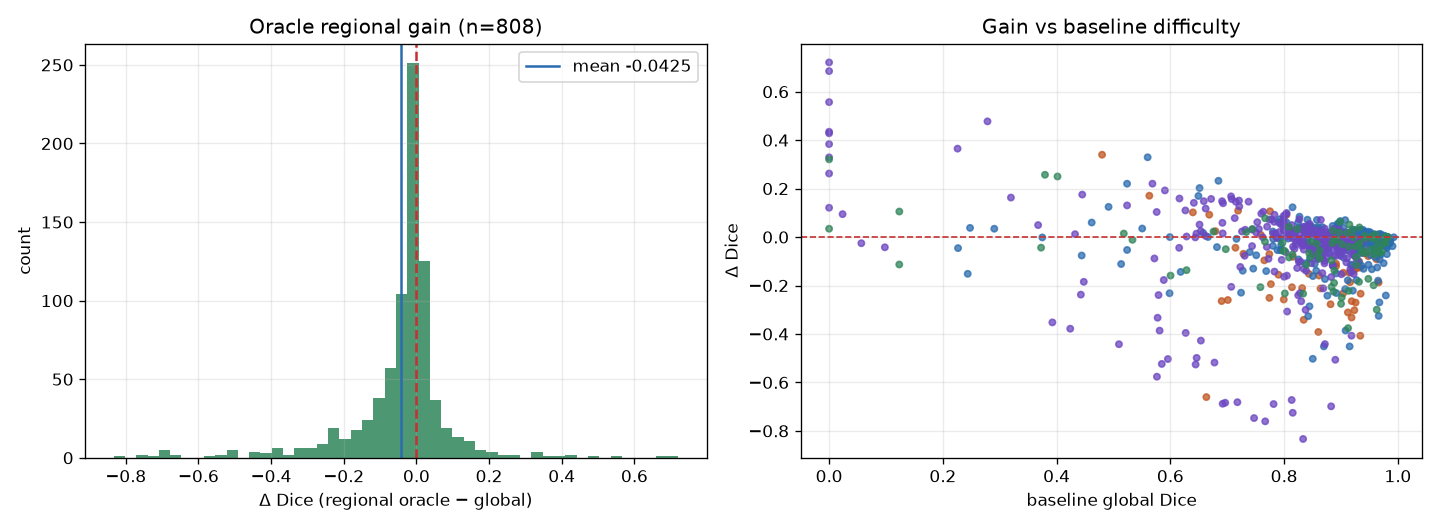

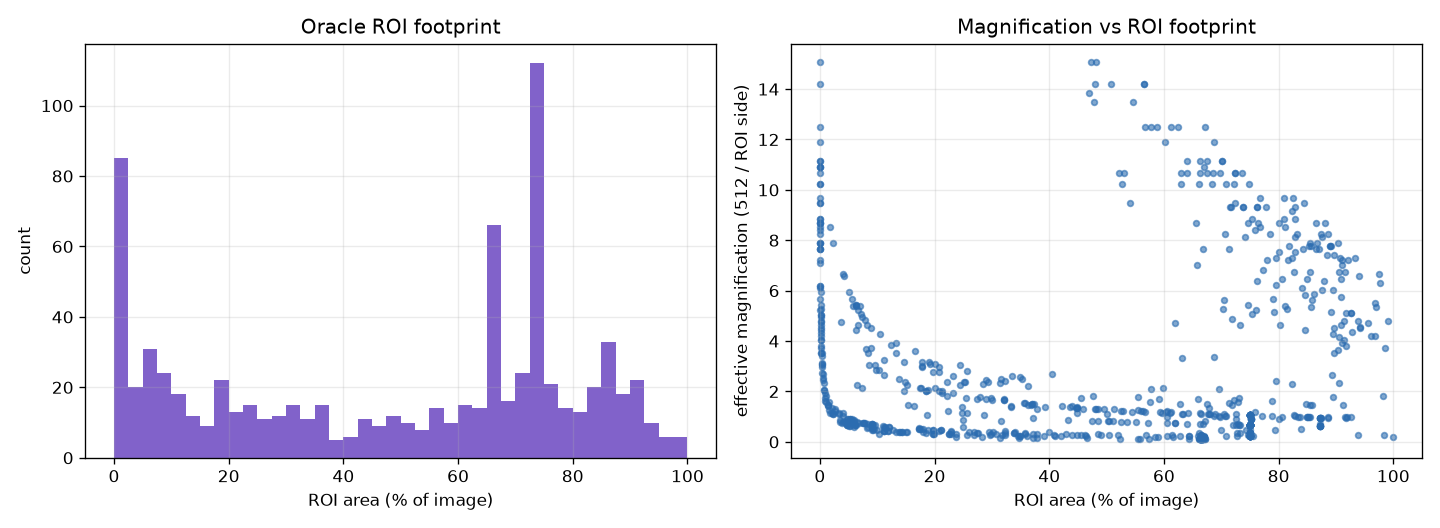

In [9]:
RG = load("phase22_oracle_regional_intervention.json")
if RG:
    rrf = load("phase22_regional_fidelity.json")
    display(sty(pd.DataFrame([
        {"item": "region fidelity max |dp| (square)", "value": rrf.get("max_abs_probability_difference_square")},
        {"item": "region fidelity thresholded px", "value": rrf.get("total_thresholded_disagreement_pixels")},
        {"item": "ROI margin", "value": RG.get("roi_rule", {}).get("margin")},
        {"item": "expanded extent factor", "value": RG.get("roi_rule", {}).get("expanded_extent_factor")},
        {"item": "re-centred after clip", "value": RG.get("roi_rule", {}).get("recentre_after_clip")},
        {"item": "decision rule", "value": RG.get("decision_rule")},
    ]), "p22_reg_spec", value="{!s}"))

    for v, s in RG.get("summaries", {}).items():
        print(f"[{v}] n_ok={s.get('n_ok')} n_no_roi={s.get('n_no_roi')} "
              f"mean_delta(exec)={s.get('mean_delta_dice_on_ok')} "
              f"ITT={s.get('mean_delta_dice_intent_to_treat')}")
    print()
    print(RG.get("interpretation_guard"))

gdom = table("phase22_oracle_gain_by_domain.csv")
if len(gdom):
    display(sty(gdom, "p22_reg_dom"))

# Per-image regional intervention table (the raw evidence behind the summaries
# above and behind the harm/regret sections that follow).
_rpi = table("phase22_regional_intervention_per_image.csv")
if len(_rpi):
    _ok = _rpi[_rpi["oracle_status"] == "OK"] if "oracle_status" in _rpi.columns else _rpi
    display(sty(_rpi.head(10), "p22_reg_perimg_head"))
    print(f"phase22_regional_intervention_per_image.csv: {len(_rpi)} rows | "
          f"{len(_ok)} with oracle_status=OK")

# Oracle ROI geometry — the footprint and effective magnification of the
# oracle regional crop (the evidence behind the p22_regional_roi_geometry figure).
_rgeo = table("phase22_roi_geometry.csv")
if len(_rgeo):
    display(sty(_rgeo.head(10), "p22_reg_roi_geo_head"))
    print(f"phase22_roi_geometry.csv: {len(_rgeo)} rows | "
          f"columns {list(_rgeo.columns)}")

show("phase22_regional_gain_distribution.png")
show("phase22_regional_roi_geometry.png")

## 10. Benefit heterogeneity (§15) — is the gain broad or concentrated?

In [10]:
HET = load("phase22_benefit_heterogeneity.json")
if HET:
    g = HET.get("gain_distribution_executed", {})
    display(sty(pd.DataFrame([
        {"item": "n executed", "value": HET.get("n_executed")},
        {"item": "mean delta Dice (executed)", "value": g.get("mean_delta_dice")},
        {"item": "median delta Dice (executed)", "value": g.get("median_delta_dice")},
        {"item": "p05 / p95", "value": f"{g.get('p05')} / {g.get('p95')}"},
        {"item": "improved / worsened / unchanged",
         "value": f"{g.get('n_positive')} / {g.get('n_negative')} / {g.get('n_zero')}"},
        {"item": "share improved", "value": g.get("share_positive")},
        {"item": "Gini of positive benefit", "value": HET.get("concentration", {}).get("gini_of_positive_benefit")},
        {"item": "top-10% share of benefit",
         "value": HET.get("concentration", {}).get("share_of_positive_benefit_from_top_10pct_of_benefiting_cases")},
        {"item": "r(gain, baseline Dice)", "value": HET.get("correlates_of_gain", {}).get("pearson_r_baseline_global_dice")},
        {"item": "r(gain, ROI area fraction)", "value": HET.get("correlates_of_gain", {}).get("pearson_r_roi_area_fraction")},
    ]), "p22_het", value="{!s}"))
    display(sty(pd.DataFrame(HET.get("per_domain", [])), "p22_het_dom"))
ht = table("phase22_benefit_heterogeneity.csv")
if len(ht):
    display(sty(ht, "p22_het_dec"))

,item,value
0,n executed,808
1,mean delta Dice (executed),-0.042477861137391895
2,median delta Dice (executed),-0.013680136565675599
3,p05 / p95,-0.30159923499591623 / 0.11483966404441578
4,improved / worsened / unchanged,271 / 536 / 1
5,share improved,0.3353960396039604
6,Gini of positive benefit,0.6439926672758494
7,top-10% share of benefit,0.49243071435177627
8,"r(gain, baseline Dice)",-0.21182609696098065
9,"r(gain, ROI area fraction)",0.14525406370401153


,dataset,n_executed,mean_delta,median_delta,sd_delta,p05_delta,p95_delta,n_positive,n_negative,share_positive,sum_positive,sum_negative
0,ISIC,357,-0.025321,-0.008814,0.082137,-0.174198,0.054864,112,244,0.313725,3.722801,-12.762343
1,BUSI,84,-0.093377,-0.055888,0.145460,-0.329020,0.100399,16,68,0.190476,1.197592,-9.041267
2,KVASIR,87,-0.050773,-0.038708,0.110805,-0.233406,0.073236,24,63,0.275862,1.479716,-5.896926
3,KUB,280,-0.046506,-0.011654,0.208467,-0.507103,0.163201,119,161,0.425000,10.595560,-23.617245


,stratified_by,decile,n,mean_delta,sum_delta,n_improved,n_worsened,mean_value
0,baseline_global_dice,D01,81,0.019329,1.565662,46,34,0.422981
1,baseline_global_dice,D02,81,-0.065658,-5.318265,42,39,0.733389
2,baseline_global_dice,D03,81,-0.054068,-4.379536,37,44,0.811947
3,baseline_global_dice,D04,80,-0.057895,-4.631581,28,52,0.849834
4,baseline_global_dice,D05,81,-0.068625,-5.558589,23,58,0.877990
5,baseline_global_dice,D06,81,-0.038776,-3.140881,26,55,0.900972
6,baseline_global_dice,D07,80,-0.071795,-5.743599,18,62,0.920522
7,baseline_global_dice,D08,81,-0.032175,-2.606196,22,59,0.938000
8,baseline_global_dice,D09,81,-0.036194,-2.931754,17,64,0.959506
9,baseline_global_dice,D10,81,-0.019474,-1.577371,12,69,0.976399


## 11. Oracle accept-if-beneficial ceiling (§16) and routing regret (§20)

The accept-if-beneficial policy is a **perfect selector**: it applies the regional arm only
where it strictly helps. It is the **ceiling of any routing policy** — oracle or learned — and
it is **not deployable**. The rule-based policies use **predicted information only** and are
the honest, deployable-shaped comparison.

,item,value
0,acceptance rate,0.335396
1,always-global pooled Dice,0.8390402334224809
2,always-regional pooled Dice,0.7965623722850891
3,ORACLE ceiling pooled Dice,0.8600744777001257
4,ceiling gain over always-global,0.021034244277644776
5,is deployable,False
6,uses ground truth,True


this is the ceiling of ANY routing policy. It is not an achieved result and no deployable method may be described as attaining it.


,policy,uses_ground_truth,deployable_shape,n_routed_to_regional,fraction_routed_to_regional,macroR_dice_pooled,mean_dice_executed_only,improvement_over_always_global,change_vs_always_regional,regret_vs_oracle_ceiling
0,ALWAYS_GLOBAL,False,True,0,0.000000,0.839040,nan,0.000000,0.042478,0.021034
1,ALWAYS_REGIONAL_ORACLE,False,True,808,1.000000,0.796562,0.796562,-0.042478,0.000000,0.063512
2,ORACLE_ACCEPT_IF_BENEFICIAL,True,False,271,0.335396,0.860074,0.837814,0.021034,0.063512,0.000000
3,PRED_ROI_EXISTS,False,True,808,1.000000,0.796562,0.796562,-0.042478,0.000000,0.063512
4,PRED_ROI_EXISTS_AND_BASELINE_BELOW_MEDIAN,False,True,404,0.500000,0.816364,0.693602,-0.022676,0.019802,0.043710
5,PRED_ACCEPT_IF_PREDICTED_BENEFICIAL,False,True,236,0.292079,0.851804,0.830373,0.012764,0.055242,0.008270


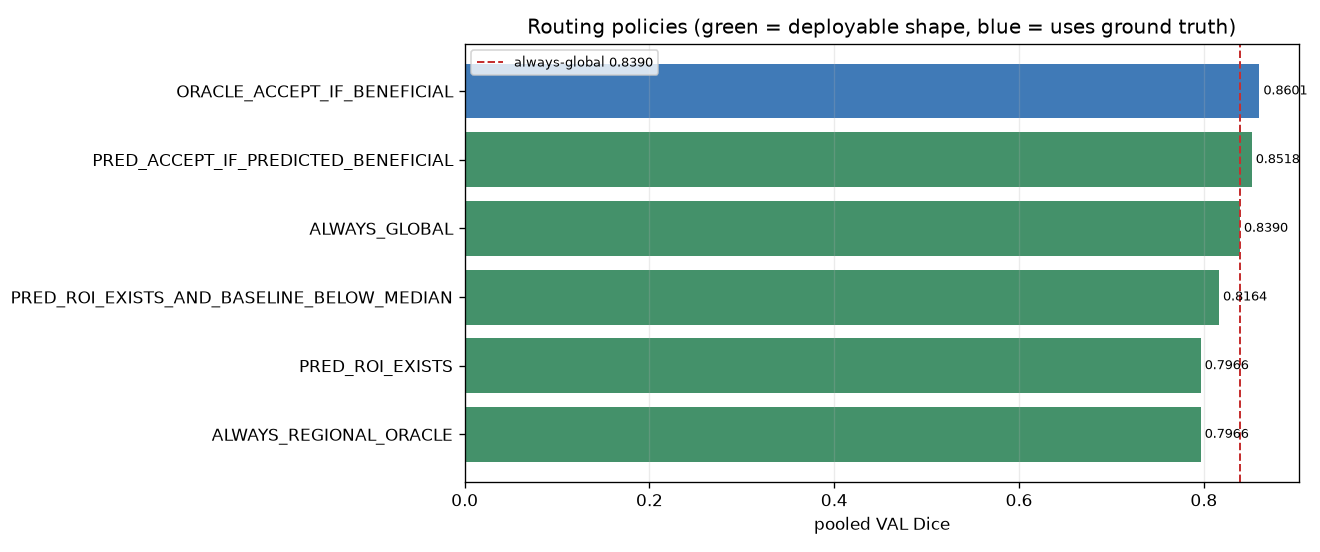

In [11]:
ACC = load("phase22_oracle_accept_if_beneficial.json")
REG = load("phase22_routing_regret.json")
if ACC:
    display(sty(pd.DataFrame([
        {"item": "acceptance rate", "value": ACC.get("acceptance_rate")},
        {"item": "always-global pooled Dice", "value": ACC.get("baseline_always_global_pooled_dice")},
        {"item": "always-regional pooled Dice", "value": ACC.get("baseline_always_regional_pooled_dice")},
        {"item": "ORACLE ceiling pooled Dice", "value": ACC.get("oracle_ceiling_pooled_dice")},
        {"item": "ceiling gain over always-global", "value": ACC.get("ceiling_gain_over_always_global")},
        {"item": "is deployable", "value": ACC.get("is_deployable")},
        {"item": "uses ground truth", "value": ACC.get("uses_ground_truth")},
    ]), "p22_ceil", value="{!s}"))
    print(ACC.get("forbidden_claim"))
rt = table("phase22_routing_regret.csv")
if len(rt):
    display(sty(rt, "p22_regret"))
show("phase22_routing_regret.png")

## 12. Harm analysis (§22) — where does the regional arm make things worse?

,item,value
0,n executed,808.0
1,n harmed,536.0
2,harm rate (executed),0.663366
3,harm rate (ITT),0.663366
4,mean harm,-0.09574212905848825
5,worst harm,-0.8334218445650708
6,total harm magnitude,-51.3177811753497
7,net gain (executed),-34.32211179901265


,dataset,n_executed,n_harmed,harm_rate,mean_harm,worst_harm,total_harm
0,ISIC,357,244,0.683473,-0.052305,-0.502526,-12.762343
1,BUSI,84,68,0.809524,-0.132960,-0.660536,-9.041267
2,KVASIR,87,63,0.724138,-0.093602,-0.375911,-5.896926
3,KUB,280,161,0.575000,-0.146691,-0.833422,-23.617245


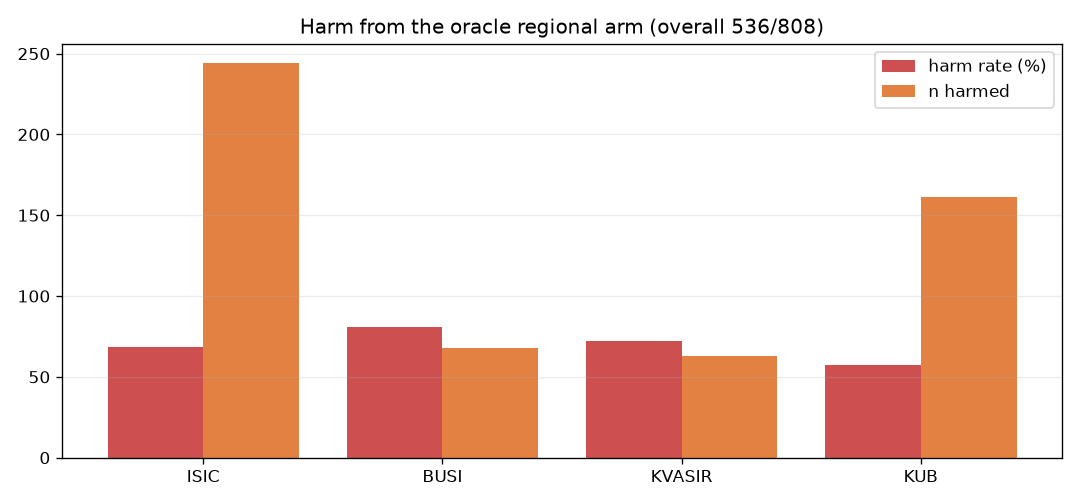

In [12]:
HARM = load("phase22_harm_analysis.json")
if HARM:
    display(sty(pd.DataFrame([
        {"item": "n executed", "value": HARM.get("n_executed")},
        {"item": "n harmed", "value": HARM.get("n_harmed")},
        {"item": "harm rate (executed)", "value": HARM.get("harm_rate_among_executed")},
        {"item": "harm rate (ITT)", "value": HARM.get("harm_rate_intent_to_treat")},
        {"item": "mean harm", "value": HARM.get("mean_harm")},
        {"item": "worst harm", "value": HARM.get("worst_harm")},
        {"item": "total harm magnitude", "value": HARM.get("total_harm_magnitude")},
        {"item": "net gain (executed)", "value": HARM.get("net_gain_executed")},
    ]), "p22_harm", value="{!s}"))
    display(sty(pd.DataFrame(HARM.get("harm_by_domain", [])), "p22_harm_dom"))
show("phase22_regional_harm.png")

## 13. Prediction-derived ROI diagnostic (§18) — the deployable-shaped variant

The ROI comes from the **model's own thresholded prediction**, never the ground truth. It
inherits every failure of the global pass; in particular a **total miss yields no ROI at
all**, so the path fails exactly where recovery is most needed. This is a diagnosed
limitation, not a proposed method.

In [13]:
ROI = load("phase22_prediction_derived_roi.json")
if ROI:
    display(sty(pd.DataFrame([
        {"item": "n total", "value": ROI.get("n_total")},
        {"item": "n with predicted ROI", "value": ROI.get("n_predicted_roi_ok")},
        {"item": "n NO_PREDICTED_ROI", "value": ROI.get("n_no_predicted_roi")},
        {"item": "NO_PREDICTED_ROI rate", "value": ROI.get("no_predicted_roi_rate")},
        {"item": "mean delta Dice (ITT)", "value": ROI.get("mean_predicted_delta_dice_intent_to_treat")},
        {"item": "mean delta Dice (executed)", "value": ROI.get("mean_predicted_delta_dice_on_executed")},
        {"item": "corr(predicted gain, oracle gain)", "value": ROI.get("correlation_predicted_vs_oracle_gain")},
    ]), "p22_roi", value="{!s}"))
    print(ROI.get("interpretation_guard"))

,item,value
0,n total,808.0
1,n with predicted ROI,808.0
2,n NO_PREDICTED_ROI,0.0
3,NO_PREDICTED_ROI rate,0.0
4,mean delta Dice (ITT),-0.06021763953686703
5,mean delta Dice (executed),-0.06021763953686703
6,"corr(predicted gain, oracle gain)",0.68391404684425


this is a diagnostic of what a TRIVIAL, UNTRAINED prediction-derived ROI achieves. It is not a benefit predictor, not a router, and not a proposed method. Any stronger claim would require training, which Phase 22 forbids.


## 14. Uncertainty vs benefit (§19) — is there a cheap deployable signal?

A router needs a signal that predicts where the regional arm would help. These correlations
use the **frozen probability maps only** (no new inference) and are computed **post hoc on
VAL**. They are **descriptive**: no threshold was fitted, no policy selected, no training
performed.

**GT-free and ground-truth-derived signals are separated.** A signal is only *deployable*
if it can be computed **without ground truth**, **before** refinement, and **at inference
time**. The frozen analysis originally ranked `recall` as the best *deployable* signal;
that was **invalid**, because recall requires the ground-truth mask.

**The figure below is generated from the corrected GT-free table**
(`reports/tables/phase22_gt_free_proxy_vs_benefit.csv`). Its **left panel** shows the
deployable (GT-free) ranking only. Where a second panel is present it is explicitly titled
`POST_HOC_GT_AWARE_DIAGNOSTIC` — those associations require ground truth and are **not**
deployable. No ground-truth-derived metric is presented as a routable signal.

GT-free deployable ranking (uses_GT = False only):


,rank,signal,spearman_r,pearson_r,abs_spearman,roc_auc,pr_auc,n
0,1,predicted_roi_side,-0.068947,-0.009414,0.068947,0.418771,0.299446,808
1,2,frac_prob_within_0p02_of_boundary,0.057256,0.080695,0.057256,0.502639,0.348121,808
2,3,frac_prob_within_0p05_of_boundary,0.056407,0.079321,0.056407,0.502625,0.346722,808
3,4,predicted_roi_area_fraction,0.056232,0.132519,0.056232,0.494609,0.343328,808
4,5,mean_boundary_margin,-0.048123,-0.079176,0.048123,0.502584,0.410401,808
5,6,entropy_proxy_mean,0.047133,0.081151,0.047133,0.496375,0.334827,808
6,7,task_id,-0.021310,-0.056670,0.021310,0.555055,0.380560,808
7,8,pred_foreground_fraction,0.020092,0.079276,0.020092,0.462193,0.307624,808


Post-hoc GROUND-TRUTH associations (NOT deployable):


,signal,uses_GT,available_before_refinement,available_at_inference,target,diagnostic_role,n,pearson_r,spearman_r,abs_spearman
0,oracle_delta_dice,True,False,False,oracle_delta_dice,POST_HOC_GT_ASSOCIATION_DIAGNOSTIC,808,1.000000,1.000000,1.000000
1,predicted_delta_dice,True,False,False,oracle_delta_dice,POST_HOC_GT_ASSOCIATION_DIAGNOSTIC,808,0.683914,0.773859,0.773859
2,mce,True,False,False,oracle_delta_dice,POST_HOC_GT_ASSOCIATION_DIAGNOSTIC,808,0.058751,0.185661,0.185661
3,recall,True,False,False,oracle_delta_dice,POST_HOC_GT_ASSOCIATION_DIAGNOSTIC,808,-0.100461,0.140902,0.140902
4,precision,True,False,False,oracle_delta_dice,POST_HOC_GT_ASSOCIATION_DIAGNOSTIC,808,-0.257342,-0.125547,0.125547
5,iou,True,False,False,oracle_delta_dice,POST_HOC_GT_ASSOCIATION_DIAGNOSTIC,808,-0.160459,-0.119255,0.119255
6,dice,True,False,False,oracle_delta_dice,POST_HOC_GT_ASSOCIATION_DIAGNOSTIC,808,-0.220519,-0.119255,0.119255
7,ece,True,False,False,oracle_delta_dice,POST_HOC_GT_ASSOCIATION_DIAGNOSTIC,808,0.109341,0.118910,0.118910
8,mcc,True,False,False,oracle_delta_dice,POST_HOC_GT_ASSOCIATION_DIAGNOSTIC,808,-0.222425,-0.109862,0.109862
9,brier,True,False,False,oracle_delta_dice,POST_HOC_GT_ASSOCIATION_DIAGNOSTIC,808,0.105303,0.085351,0.085351


these are DESCRIPTIVE post-hoc correlations on the same frozen VAL population; they are weak in magnitude and no threshold was fitted and no policy was selected. The GT-free ranking does not establish a deployable router.
Best GT-free signal: predicted_roi_side (|rho|=0.0689) — weak magnitude; descriptive only, no threshold fitted, no router selected.


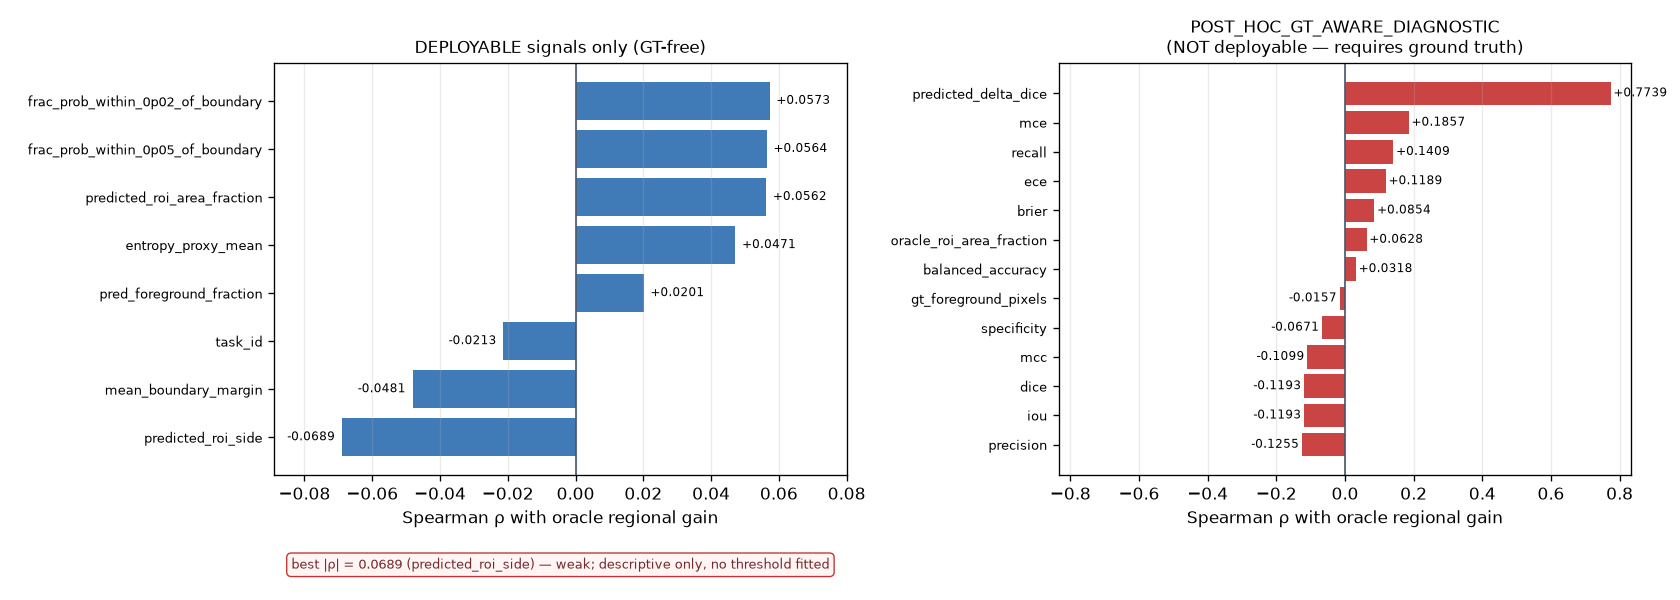

In [14]:
REP = load("phase22_postfreeze_semantic_repair.json")
_gf = TAB / "phase22_gt_free_proxy_vs_benefit.csv"
_ga = TAB / "phase22_gt_aware_posthoc_associations.csv"
# FAIL CLOSED: the GT-free deployable ranking is mandatory. We must never fall
# back to the frozen GT-mixed JSON (phase22_uncertainty_vs_benefit.json,
# ranked_abs_spearman), which mixed ground-truth-derived quantities such as
# `recall` into the "deployable" ranking and presented recall as the winner.
if not REP:
    raise FileNotFoundError(
        "phase22_postfreeze_semantic_repair.json is missing — refusing to fall "
        "back to the GT-mixed phase22_uncertainty_vs_benefit.json ranking")
if not _gf.exists():
    raise FileNotFoundError(f"required GT-free table missing: {_gf}")
print("GT-free deployable ranking (uses_GT = False only):")
display(sty(pd.DataFrame(REP.get("gt_free_deployable_ranking", [])), "p22_unc_gtfree"))
if _ga.exists():
    print("Post-hoc GROUND-TRUTH associations (NOT deployable):")
    display(sty(pd.read_csv(_ga), "p22_unc_gtaware"))
print(REP.get("best_gt_free_signal_interpretation"))
if _gf.exists():
    _gfd = pd.read_csv(_gf)
    assert not bool(_gfd["uses_GT"].astype(str).str.lower().eq("true").any()), \
        "GT-free table contains GT-derived rows"
    _b = _gfd.reindex(_gfd["abs_spearman"].abs().sort_values(ascending=False).index).iloc[0]
    print(f"Best GT-free signal: {_b['signal']} (|rho|={abs(_b['spearman_r']):.4f}) — "
          "weak magnitude; descriptive only, no threshold fitted, no router selected.")
show("phase22_uncertainty_vs_benefit.png")

## 15. Resource frontier (§17) and conditional-compute envelopes (§24)

The regional pass always costs **one full 512 forward regardless of crop size**, because the
crop is resampled to 512. Conditional compute therefore saves **executions**, not resolution:
a smaller crop does **not** cost less. This is stated explicitly so the frontier is not
over-read.

,policy,n_regional,fraction_regional,mean_macs_gmacs,multiplier_vs_always_global,pooled_dice,gain_over_always_global,regret_vs_oracle_ceiling,gmacs_per_dice_point
0,ALWAYS_GLOBAL,0,0.000000,31.551700,1.000000,0.839040,0.000000,0.021034,37.604563
1,ALWAYS_REGIONAL_ORACLE,808,1.000000,63.103500,2.000000,0.796562,-0.042478,0.063512,79.219762
2,ORACLE_ACCEPT_IF_BENEFICIAL,271,0.335396,42.134100,1.335396,0.860074,0.021034,0.000000,48.988862
3,PRED_ROI_EXISTS,808,1.000000,63.103500,2.000000,0.796562,-0.042478,0.063512,79.219762
4,PRED_ACCEPT_IF_PREDICTED_BENEFICIAL,236,0.292079,40.767300,1.292079,0.851804,0.012764,0.008270,47.860004


global pass MACs @512: 31551740928
regional pass MACs @512: 31551740928
the regional pass always costs ONE full 512x512 forward regardless of crop size, because the crop is resampled to 512. Conditional compute therefore saves EXECUTIONS, not resolution. A smaller crop does NOT cost less.
MAC counts at non-512 resolutions are scaled by (size/512)**2; this is exact for a fully convolutional stack at fixed channel widths and is an approximation for the true graph


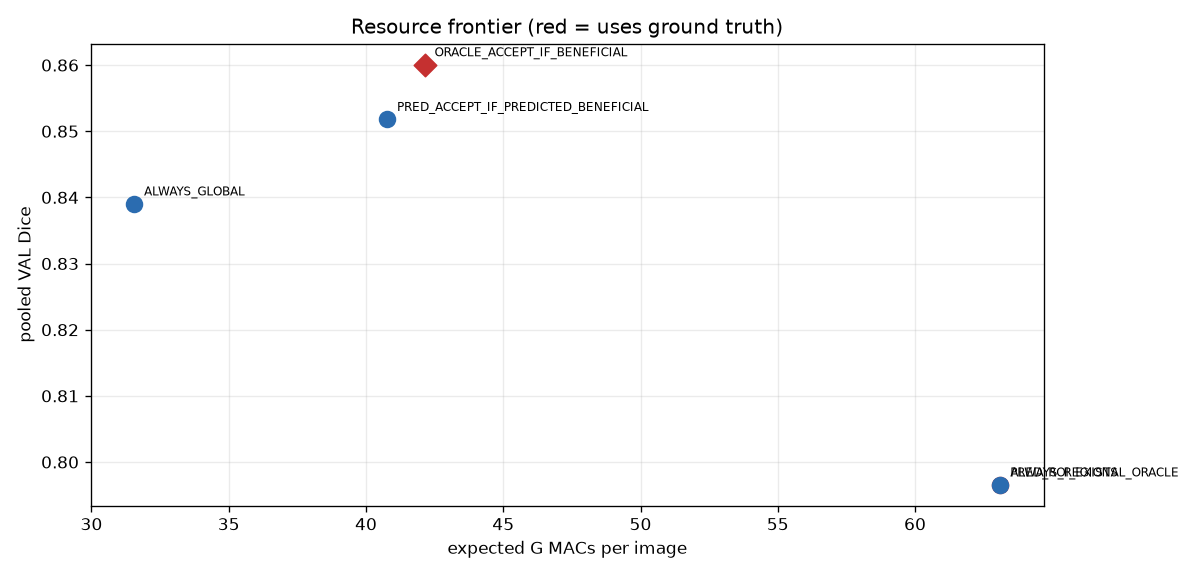

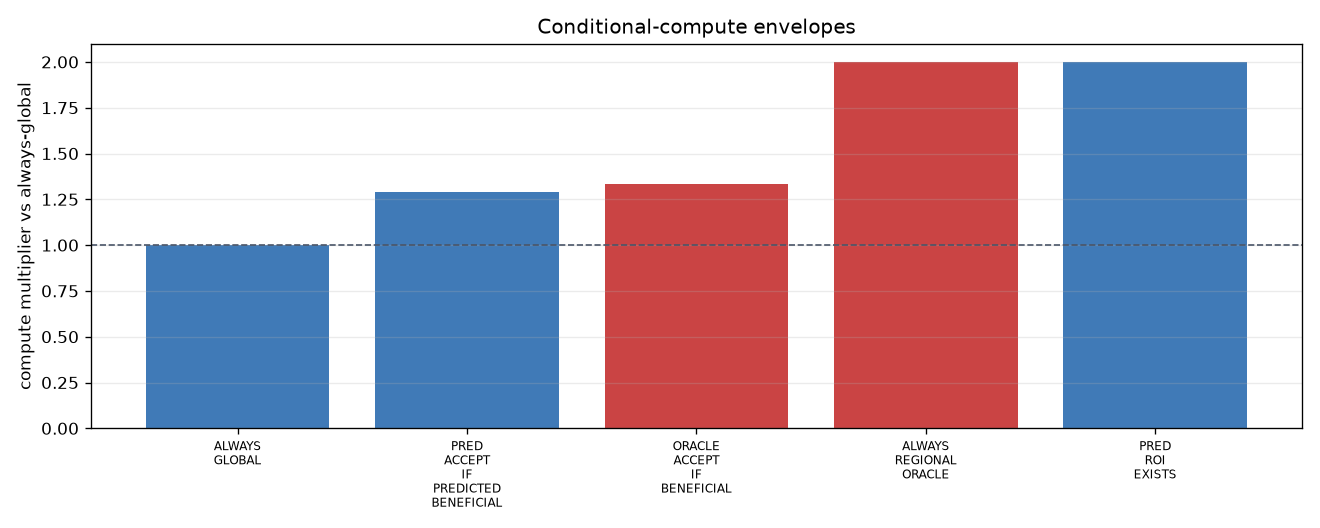

In [15]:
ENV = load("phase22_conditional_compute_envelopes.json")
FR = load("phase22_resource_frontier.json")
envf = table("phase22_conditional_compute_envelopes.csv")
if len(envf):
    display(sty(envf, "p22_env"))
if ENV:
    print("global pass MACs @512:", ENV.get("global_pass_macs_at_512"))
    print("regional pass MACs @512:", ENV.get("regional_pass_macs_at_512"))
    print(ENV.get("important_caveat"))
    print(ENV.get("analytical_approximation"))
show("phase22_resource_frontier.png")
show("phase22_resource_envelopes.png")

## 16. Resource gap (§23) — six-model panel and the absolute-cost warning

Cost is a **lower bound**: the analytical count covers closed-form `Conv2d`/`Linear` MACs
only, excluding GroupNorm, SiLU, pooling, bilinear interpolation, FiLM modulation and
sigmoid. Parameters do **not** predict compute — the cost is resolution-driven.

,item,value
0,reference parameters,3523001
1,reference G MACs @512,31.5517
2,param rank of reference,1
3,compute rank of reference,1
4,is small in absolute terms,False


the reference is the LIGHTEST of the six-model panel, but ~31.6 G MACs per image is NOT a small absolute cost. 'Lightest of the panel' must never be reported as 'fit for constrained deployment'. No pruning, quantization, distillation, or NAS has been performed and none is claimed.


,model_key,display_name,params,gmacs,params_rank,gmacs_rank,params_ratio_vs_medfilm,gmacs_ratio_vs_medfilm,params_lower_bound_macs
0,global_medfilm,Global MedFiLM,3523001,31.551700,1,1,1.000000,1.000000,True
1,unet,U-Net,7763041,46.137300,2,2,2.203500,1.462300,True
2,attention_unet,Attention U-Net,7851285,47.219000,3,3,2.228600,1.496600,True
3,deeplabv3plus,DeepLabV3+,40347041,69.139400,6,4,11.452500,2.191300,True
4,transformer_mit_unet,Transformer/MiT,16347777,99.098600,5,5,4.640300,3.140800,True
5,unetpp,U-Net++,9159681,137.942300,4,6,2.600000,4.371900,True


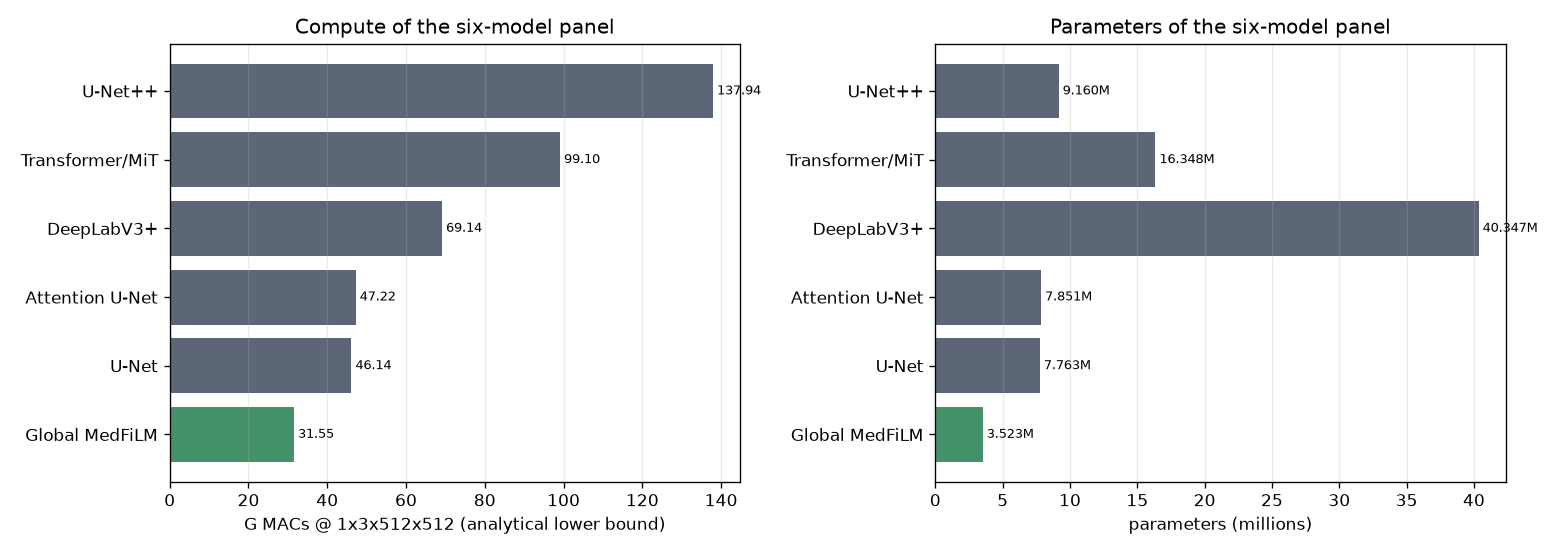

In [16]:
GAP = load("phase22_resource_gap.json")
if GAP:
    display(sty(pd.DataFrame([
        {"item": "reference parameters", "value": GAP.get("reference_params")},
        {"item": "reference G MACs @512", "value": GAP.get("reference_gmacs_at_512")},
        {"item": "param rank of reference", "value": GAP.get("param_rank_of_reference")},
        {"item": "compute rank of reference", "value": GAP.get("gmacs_rank_of_reference")},
        {"item": "is small in absolute terms", "value": GAP.get("absolute_cost_statement", {}).get("is_small_in_absolute_terms")},
    ]), "p22_gap", value="{!s}"))
    print(GAP.get("absolute_cost_statement", {}).get("note"))
    display(sty(pd.DataFrame(GAP.get("panel", [])), "p22_gap_panel"))
show("phase22_resource_six_model.png")

## 17. CPU baseline (§25) — measurement, not model

In [17]:
CPU = load("phase22_cpu_baseline.json")
if CPU:
    display(sty(pd.DataFrame(CPU.get("rows", [])), "p22_cpu"))
    print("threads:", CPU.get("threads"),
          "| batch:", CPU.get("batch_size"),
          "| AMP:", CPU.get("amp"),
          "| measurement_only:", CPU.get("measurement_only"))
    print(CPU.get("rss_note"))
    print(CPU.get("note"))

,size,device,n_iter,mean_seconds,median_seconds,min_seconds,max_seconds,stdev_seconds,mean_process_rss_mib,max_process_rss_mib,analytical_macs
0,256,cpu,3,0.093274,0.093498,0.089901,0.096422,0.002667,646.054688,646.078125,7887935232
1,512,cpu,3,0.389540,0.369271,0.364405,0.434944,0.032167,912.829427,913.179688,31551740928
2,768,cpu,3,0.768402,0.763385,0.761340,0.780482,0.008582,1322.994792,1323.007812,70991417088


threads: 8 | batch: 1 | AMP: False | measurement_only: True
process RSS (working set) is the metric; tracemalloc was rejected because it reports 0.0 for a torch forward pass - the tensor arena is C-allocated and invisible to it
these timings are host-specific and are reported as an absolute baseline, not as a hardware-independent quantity. CPU timings are recorded separately from the analytical MAC count, which is device-independent.


## 18. KUB TINY analysis (§26)

The TINY stratum (`component_ratio <= Q25` of the frozen `kub_size_clean_v3_v1` taxonomy) is
the project's central difficulty. TINY was **not** optimised on: no component of the
reference model was specialised for it.

**Reading guard on the stratum figure below.** The bars are *observed* mean Dice per stratum;
TINY shows the lowest observed mean Dice. The figure must **not** be read as establishing a
statistically significant TINY improvement of any kind. The observed TINY oracle regional gain
is `+0.013197` Dice, but its paired 95% CI `[-0.084062, +0.105133]` **includes zero**
(p = 0.763); the TINY effect is therefore **descriptive only**.

,item,value
0,taxonomy,kub_size_clean_v3_v1
1,stratum definition,"TINY = component_ratio <= Q25 = 0.0001497998649691358 (frozen, lower-inclusive)"
2,TINY optimised on,False


,stratum,n,mean_dice,median_dice,p05_dice,min_dice,mean_recall,mean_precision,n_dice_below_0p5
0,LARGE,13,0.708226,0.832163,0.034014,0.000000,nan,nan,2
1,MEDIUM,27,0.699821,0.765957,0.429222,0.272727,nan,nan,4
2,ROI_NOT_PRIMARY_BINNED,177,0.847420,0.862713,0.718844,0.559441,nan,nan,0
3,SMALL,19,0.654176,0.666667,0.372857,0.000000,nan,nan,2
4,TINY,44,0.532079,0.652618,0.000000,0.000000,nan,nan,14


,n,mean_global_dice,mean_oracle_delta_dice,mean_oracle_delta_dice_executed_only,mean_predicted_delta_dice,n_oracle_improved,n_oracle_harmed,mean_roi_area_fraction,n_no_predicted_roi,bootstrap_vs_global
0,44,0.532079,0.013197,0.013197,-0.111028,32,12,0.009228,0,"{'delta': 0.01319659611612023, 'ci_low': -0.0840619700020022, 'ci_high': 0.1051333292147158, 'p_value': 0.763, 'ci_excludes_zero': False, 'n_boot': 2000, 'seed': 42, 'alpha': 0.05, 'unit': 'image', 'paired': True, 'domain_stratified': True, 'n_strata': 1}"


Required wording (B5): KUB TINY was the only frozen size stratum with a positive observed mean oracle regional gain (+0.013197 Dice), but the paired 95% CI [-0.084062, 0.105133] includes zero (p=0.763); therefore the TINY effect is descriptive and not statistically established.
This does NOT weaken the useful finding: regional benefit is strongly heterogeneous, and always-on regional processing is harmful in aggregate.


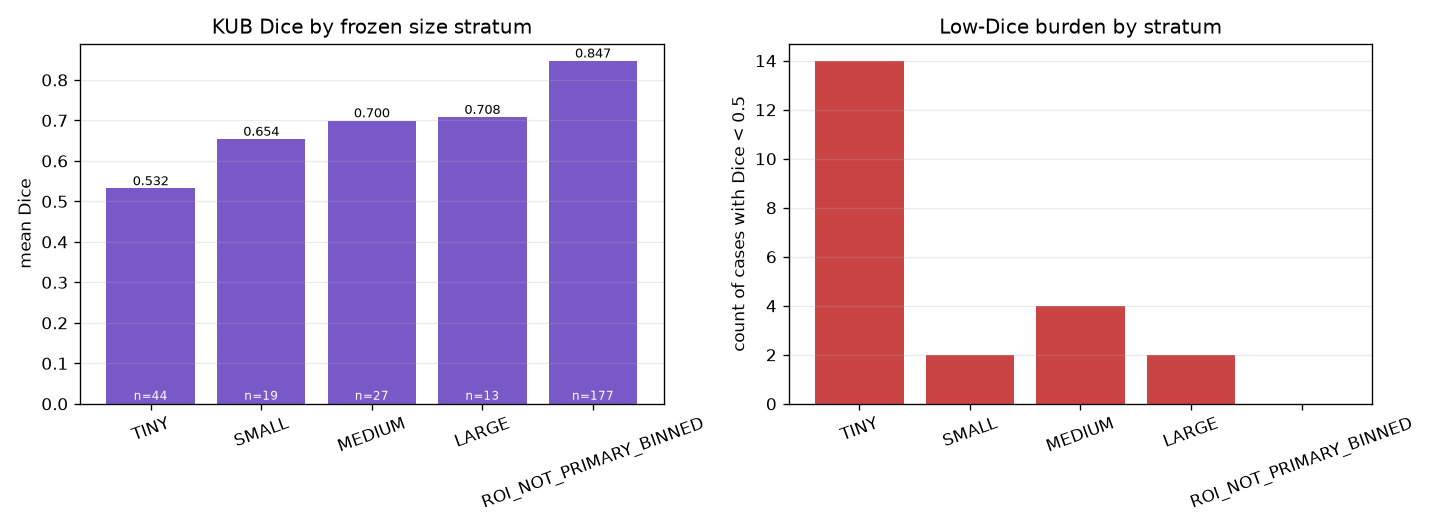

In [18]:
TINY = load("phase22_kub_tiny_analysis.json")
if TINY:
    display(sty(pd.DataFrame([
        {"item": "taxonomy", "value": TINY.get("taxonomy_id")},
        {"item": "stratum definition", "value": TINY.get("stratum_definition")},
        {"item": "TINY optimised on", "value": TINY.get("tiny_optimised_on")},
    ]), "p22_tiny_spec", value="{!s}"))
    if isinstance(TINY.get("strata"), list):
        display(sty(pd.DataFrame(TINY["strata"]), "p22_tiny"))
    if "tiny_stratum_regional_gain" in TINY:
        display(sty(pd.DataFrame([TINY["tiny_stratum_regional_gain"]]), "p22_tiny_gain"))
        _tg = TINY["tiny_stratum_regional_gain"]
        _bt = _tg.get("bootstrap_vs_global") or {}
        print("Required wording (B5): KUB TINY was the only frozen size stratum with a "
              f"positive observed mean oracle regional gain (+{_tg.get('mean_oracle_delta_dice'):.6f} Dice), "
              f"but the paired 95% CI [{_bt.get('ci_low'):.6f}, {_bt.get('ci_high'):.6f}] includes zero "
              f"(p={_bt.get('p_value')}); therefore the TINY effect is descriptive and not "
              "statistically established.")
        print("This does NOT weaken the useful finding: regional benefit is strongly "
              "heterogeneous, and always-on regional processing is harmful in aggregate.")
show("phase22_kub_strata.png")

## 19. Domain preservation (§27) and statistics consolidation (§28)

The reference is frozen, so **no per-domain property of the reference can change** in Phase
22. Domain preservation is therefore a statement about the **diagnostic arms only**.

In [19]:
DOM = load("phase22_domain_preservation.json")
if DOM:
    display(sty(pd.DataFrame(DOM.get("per_domain", [])), "p22_dom"))
    print("reference unchanged:", DOM.get("reference_unchanged", {}).get("matches_frozen_phase21_values"))
    print(DOM.get("answer_summary"))

ST = load("phase22_statistics.json")
if ST:
    print()
    display(sty(pd.DataFrame([{k: (json.dumps(v) if isinstance(v, (dict, list)) else v)
                               for k, v in c.items()} for c in ST.get("comparisons", {}).values()]),
               "p22_stats"))
    print(ST.get("ci_overlap_rule"))
    print("threshold caveat:", ST.get("threshold_rule_caveat", {}).get("rule"),
          "| residual px:", ST.get("threshold_rule_caveat", {}).get("residual_mismatch_pixels_against_stored_pred"))

,dataset,n,frozen_mean_dice,n_oracle_executed,mean_oracle_delta_dice_itt,mean_oracle_delta_dice_executed,mean_predicted_delta_dice_itt,n_oracle_improved,n_oracle_harmed,max_domain_degradation_under_any_policy
0,ISIC,357,0.897189,357,-0.025321,-0.025321,-0.030623,112,244,-0.502526
1,BUSI,84,0.858823,84,-0.093377,-0.093377,-0.106559,16,68,-0.660536
2,KVASIR,87,0.820247,87,-0.050773,-0.050773,-0.058724,24,63,-0.375911
3,KUB,280,0.764058,280,-0.046506,-0.046506,-0.084512,119,161,-0.833422


reference unchanged: True
The reference model is FROZEN and unchanged, so no per-domain property of the reference can change in Phase 22. Domain preservation is therefore a statement about the DIAGNOSTIC arms only.



,delta,ci_low,ci_high,p_value,ci_excludes_zero,n_boot,seed,alpha,unit,paired,domain_stratified,n_strata
0,-0.042478,-0.052343,-0.032363,0.000000,True,2000,42,0.050000,image,True,True,4
1,-0.042478,-0.052343,-0.032363,0.000000,True,2000,42,0.050000,image,True,True,4
2,-0.060218,-0.070553,-0.050742,0.000000,True,2000,42,0.050000,image,True,True,4
3,-0.060218,-0.070553,-0.050742,0.000000,True,2000,42,0.050000,image,True,True,4
4,-0.138240,-0.155253,-0.122172,0.000000,True,2000,42,0.050000,image,True,True,4
5,-0.036888,-0.044632,-0.029160,0.000000,True,2000,42,0.050000,image,True,True,4
6,-0.100413,-0.110645,-0.090445,0.000000,True,2000,42,0.050000,image,True,True,4


where the CI overlaps zero the arms are NOT separable and no ordering claim may be made
threshold caveat: pred = (float32(prob) >= 0.5) | residual px: 1078


## 20. Scale vs regional (§29) — which axis buys more Dice?

A direct comparison of the two candidate axes. It must be read with the guard in view: the
scale axis is a genuine (off-training-distribution) measurement, while the regional-**oracle**
axis is an **upper bound that uses ground truth**. The two are **not** comparable as methods.

,axis,value,macro_domain_dice,mean_pooled_dice,relative_cost_vs_512,mean_pooled_dice_executed,relative_cost_vs_512_always_global,uses_ground_truth
0,SCALE,256.000000,0.688499,0.700800,0.250000,nan,nan,nan
1,SCALE,512.000000,0.835343,0.839040,1.000000,nan,nan,nan
2,SCALE,768.000000,0.776819,0.802152,2.250000,nan,nan,nan
3,SCALE,1024.000000,0.682561,0.738627,4.000000,nan,nan,nan
4,REGIONAL_ORACLE,nan,0.781349,nan,nan,0.796562,2.000000,True
5,REGIONAL_PREDICTED,nan,0.765239,0.778823,nan,nan,2.000000,False
6,BASELINE,nan,0.835079,0.839040,1.000000,nan,nan,nan


the scale axis is a genuine (if off-training-distribution) measurement. The regional-ORACLE axis is an UPPER BOUND that uses ground truth. The two are NOT directly comparable as methods, and the oracle must not be presented as the better 'method'.


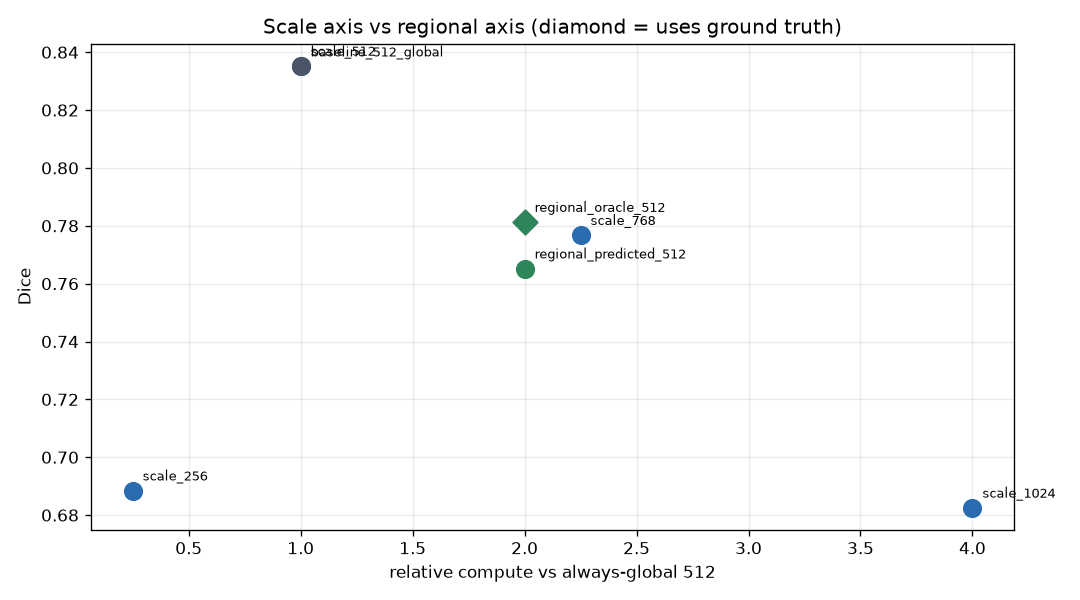

In [20]:
SVR = load("phase22_scale_vs_regional.json")
if SVR:
    rows = []
    for k, v in SVR.get("axes", {}).items():
        rows.append({"axis": k, **{kk: vv for kk, vv in v.items() if not isinstance(vv, dict)}})
    display(sty(pd.DataFrame(rows), "p22_svr"))
    print(SVR.get("verdict_guard"))
show("phase22_scale_vs_regional.png")

## 21. No-new-training audit (§38) and the future benefit-label contract (§30)

Phase 22 is forbidden to train anything. This section is the audit of that prohibition: a
static scan of every Phase-22 code file for training constructs, a check that the Phase-21
experiment and checkpoint directories are byte-unchanged, and a check that every Phase-22
audit declares zero training jobs.

In [21]:
NT = load("phase22_no_new_training_audit.json")
if NT:
    display(sty(pd.DataFrame(NT.get("checks", [])), "p22_nt"))
    print("Verdict:", NT.get("verdict"))
    print("Total forbidden hits in Phase-22 code:",
          NT.get("static_scan", {}).get("total_forbidden_construct_hits"),
          "over", NT.get("static_scan", {}).get("files_scanned"), "files")
    print("training_jobs_started:", NT.get("training_jobs_started"),
          "| optimizer constructed:", NT.get("optimizer_constructed"),
          "| backward called:", NT.get("backward_called"),
          "| checkpoint written:", NT.get("checkpoint_written"))
    print("TEST reads:", json.dumps(NT.get("test_reads", {})))

,check,pass,observed,expected,unexpected_files,note
0,phase22_code_has_no_training_constructs,True,0,0,nan,nan
1,phase21_experiment_dir_unchanged_file_set,True,"['closure.json', 'config.json', 'history.csv', 'history.json', 'phase21_checkpoint_selection_replay.json', 'phase21_training_closure.json', 'run_manifest.json', 'training_state.json']","['closure.json', 'config.json', 'history.csv', 'history.json', 'phase21_checkpoint_selection_replay.json', 'phase21_training_closure.json', 'run_manifest.json', 'training_state.json']",[],subset check: Phase 22 must not ADD any run artifact to the Phase-21 experiment directory. The expected list is the Phase-21 write-set only; a missing file is reported by 'missing_files' rather than by failing this check.
2,phase21_checkpoint_dir_only_best_last_latest,True,"['best.pt', 'last.pt', 'latest.pt']","['best.pt', 'last.pt', 'latest.pt']",nan,nan
3,no_phase22_run_lock_created,True,False,False,nan,nan
4,checkpoint_sha_unchanged,True,286689fdd5c63ad75a383151d267af8b476e7a98327632de292ce6ed5b5ba1b7,286689fdd5c63ad75a383151d267af8b476e7a98327632de292ce6ed5b5ba1b7,nan,nan
5,phase22_protocol_asserts_not_training_phase,True,False,False,nan,nan
6,all_phase22_audits_declare_no_training,True,[],[],nan,nan
7,test_reads_zero,True,"{'test_image_reads': 0, 'test_mask_reads': 0, 'test_inference': 0, 'test_visualization': 0}",all 0,nan,nan


Verdict: PHASE22_NO_NEW_TRAINING_AUDIT_PASS
Total forbidden hits in Phase-22 code: 0 over 12 files
training_jobs_started: 0 | optimizer constructed: False | backward called: False | checkpoint written: False
TEST reads: {"test_image_reads": 0, "test_mask_reads": 0, "test_inference": 0, "test_visualization": 0}


## 22. Candidate-method evidence (§31)

The evidence gathered in Phase 22 is *diagnostic*. It supports **the existence of headroom**
and **the difficulty of capturing it without training**; it does **not** support any claim
that a deployable method attains these numbers, and it says nothing about TEST.

In [22]:
CE = load("phase22_candidate_method_evidence.json")
if CE:
    for c in CE.get("candidates", []):
        print(f"--- {c.get('candidate')}  [{c.get('status')}]")
        for k, v in (c.get("evidence") or {}).items():
            print(f"      {k}: {v}")
        print(f"      supports: {c.get('supports')}")
        print(f"      does_not_support: {c.get('does_not_support')}")
    print()
    print(CE.get("verdict"))
LB = load("phase22_future_benefit_label_contract.json")
if LB:
    print()
    _ld = LB.get("label_definition", {})
    print("future label quantity:", _ld.get("quantity"))
    print("deployable geometry source:",
          _ld.get("geometry_source_required_for_a_DEPLOYABLE_label"))
    print("status:", LB.get("status"), "| is a training artifact:",
          LB.get("is_a_training_artifact"))

--- C1 REGIONAL ZOOM (oracle upper bound)  [BOUNDED_ONLY]
      oracle_accept_if_beneficial_ceiling_gain: 0.021034244277644776
      oracle_acceptance_rate: 0.335396
      oracle_mean_delta_executed: -0.042477861137391895
      oracle_harm_rate_intent_to_treat: 0.663366
      supports: a positive, measurable ceiling exists for a perfect selector on this population
      does_not_support: ['that any deployable selector attains it', 'that the gain survives on TEST (never measured)']
--- C2 PREDICTION-DERIVED ROI (untrained)  [WEAK_AS_IMPLEMENTED]
      no_predicted_roi_rate: 0.0
      mean_delta_intent_to_treat: -0.06021763953686703
      mean_delta_executed: -0.06021763953686703
      correlation_with_oracle_gain: 0.68391404684425
      supports: the ROI can be derived without ground truth, so the shape of a deployable pipeline is realisable
      does_not_support: that the untrained ROI is an effective policy; the no-ROI rate and the ITT delta are the evidence against
--- C3 SCALE (inp

## 23. Figure inventory (§32 / §33) and the explicit figure manifest

Every figure is derived deterministically (`Agg`, fixed dpi) from a persisted artifact. The
**manifest** declares the required reviewer figure set (`figure_id, section, semantic_role,
expected_to_embed, source_sha256`); the notebook embeds through it **fail-closed** — a
required figure that cannot be located, decoded or SHA-matched aborts the build rather than
silently printing "figure unavailable".

In [23]:
inv_csv = pd.read_csv(FIG / "phase22_figure_inventory.csv")     if (FIG / "phase22_figure_inventory.csv").exists() else pd.DataFrame()
man_csv = pd.read_csv(FIG / "phase22_figure_manifest.csv")     if (FIG / "phase22_figure_manifest.csv").exists() else pd.DataFrame()
if len(inv_csv):
    display(sty(inv_csv, "p22_figs"))
    print(f"{len(inv_csv)} figures listed in the inventory")
else:
    on_disk = sorted(p.name for p in FIG.glob("*.png")) if FIG.exists() else []
    display(sty(pd.DataFrame([{"figure": n} for n in on_disk]), "p22_figs"))
    print(f"{len(on_disk)} figures on disk (inventory not yet written)")
if len(man_csv):
    display(sty(man_csv, "p22_fig_manifest"))
    print(f"{len(man_csv)} figures declared in the manifest | "
          f"{int(man_csv['expected_to_embed'].sum())} required for embedding")

,name,group,file,caption
0,p22_atlas_dice_distribution,atlas,reports\figures\phase22_resource_gap\p22_atlas_dice_distribution.png,Per-image Dice distribution by domain and pooled.
1,p22_atlas_taxonomy,atlas,reports\figures\phase22_resource_gap\p22_atlas_taxonomy.png,Failure taxonomy counts overall and composition by domain.
2,p22_atlas_worst_cases,atlas,reports\figures\phase22_resource_gap\p22_atlas_worst_cases.png,Ten worst-Dice cases per domain.
3,p22_scale_curve,scale,reports\figures\phase22_resource_gap\p22_scale_curve.png,Scale sensitivity of the frozen 512-trained reference at 256/512/768/1024.
4,p22_scale_delta_ci,scale,reports\figures\phase22_resource_gap\p22_scale_delta_ci.png,"Paired Δ Dice against the 512 reference, with 95% CIs."
5,p22_regional_gain_distribution,regional,reports\figures\phase22_resource_gap\p22_regional_gain_distribution.png,Distribution of the oracle regional gain and its relation to baseline Dice.
6,p22_regional_harm,regional,reports\figures\phase22_resource_gap\p22_regional_harm.png,Harm rate and harm count per domain for the oracle regional arm.
7,p22_regional_roi_geometry,regional,reports\figures\phase22_resource_gap\p22_regional_roi_geometry.png,Oracle ROI footprint and the resulting effective magnification.
8,p22_routing_regret,routing,reports\figures\phase22_resource_gap\p22_routing_regret.png,Pooled Dice of each routing policy against the always-global baseline.
9,p22_resource_frontier,routing,reports\figures\phase22_resource_gap\p22_resource_frontier.png,Pooled Dice versus expected compute for each routing policy.


15 figures listed in the inventory


,figure_id,section,semantic_role,expected_to_embed,uses_GT,deployable_interpretation_allowed,filename,built,file,source_path,source_sha256,caption
0,p22_atlas_dice_distribution,6,DESCRIPTIVE,True,True,False,p22_atlas_dice_distribution.png,True,reports\figures\phase22_resource_gap\p22_atlas_dice_distribution.png,reports\figures\phase22_resource_gap\p22_atlas_dice_distribution.png,b45b7fd0e04326c1b5cb6c9bd3455e546635938d318343db0645ec4c74f27579,Per-image Dice distribution by domain and pooled.
1,p22_atlas_taxonomy,6,DESCRIPTIVE,True,True,False,p22_atlas_taxonomy.png,True,reports\figures\phase22_resource_gap\p22_atlas_taxonomy.png,reports\figures\phase22_resource_gap\p22_atlas_taxonomy.png,deabe018508c584a32ad6917d56b6494bea8c991a4c822cf10e067db8a3469c6,Failure taxonomy counts overall and composition by domain.
2,p22_atlas_worst_cases,6,DESCRIPTIVE,True,True,False,p22_atlas_worst_cases.png,True,reports\figures\phase22_resource_gap\p22_atlas_worst_cases.png,reports\figures\phase22_resource_gap\p22_atlas_worst_cases.png,2c468e5c28eb6c02ce75517daec3999e0d7c3c9a68375235b268e856d2ecc692,Ten worst-Dice cases per domain.
3,p22_scale_curve,11,DESCRIPTIVE,True,True,False,p22_scale_curve.png,True,reports\figures\phase22_resource_gap\p22_scale_curve.png,reports\figures\phase22_resource_gap\p22_scale_curve.png,4103d8fee3b0237ccd2a0a3a80730d5b5d38633eb17d7c70b45bbad010e6b57b,Scale sensitivity of the frozen 512-trained reference at 256/512/768/1024.
4,p22_scale_delta_ci,11,CI_CAVEATED,True,True,False,p22_scale_delta_ci.png,True,reports\figures\phase22_resource_gap\p22_scale_delta_ci.png,reports\figures\phase22_resource_gap\p22_scale_delta_ci.png,35525c8690f7c31ed92492327d59a7487baefd864079a9cc207428fda9f6f6b8,"Paired Δ Dice against the 512 reference, with 95% CIs."
5,p22_regional_gain_distribution,12,DESCRIPTIVE,True,True,False,p22_regional_gain_distribution.png,True,reports\figures\phase22_resource_gap\p22_regional_gain_distribution.png,reports\figures\phase22_resource_gap\p22_regional_gain_distribution.png,513c1140b06037aa1e0dbdd6e5a041b754619aed3499c8beab26f8360639af05,Distribution of the oracle regional gain and its relation to baseline Dice.
6,p22_regional_harm,12,DESCRIPTIVE,True,True,False,p22_regional_harm.png,True,reports\figures\phase22_resource_gap\p22_regional_harm.png,reports\figures\phase22_resource_gap\p22_regional_harm.png,cf8ccd199af5b442e0503b84211e878af5c1565c8b00efb600578a0ff660e269,Harm rate and harm count per domain for the oracle regional arm.
7,p22_regional_roi_geometry,12,DESCRIPTIVE,True,True,False,p22_regional_roi_geometry.png,True,reports\figures\phase22_resource_gap\p22_regional_roi_geometry.png,reports\figures\phase22_resource_gap\p22_regional_roi_geometry.png,c0b6060c0883ae0c323281e8f11cfc0599712e9d183ce766aeb53481ce8f0f89,Oracle ROI footprint and the resulting effective magnification.
8,p22_routing_regret,15,DESCRIPTIVE,True,True,False,p22_routing_regret.png,True,reports\figures\phase22_resource_gap\p22_routing_regret.png,reports\figures\phase22_resource_gap\p22_routing_regret.png,7b7f5c9d5846c73f458af8e7dea776483020ea2b3a1d33108b8b6f88284e5786,Pooled Dice of each routing policy against the always-global baseline.
9,p22_resource_frontier,15,DESCRIPTIVE,True,True,False,p22_resource_frontier.png,True,reports\figures\phase22_resource_gap\p22_resource_frontier.png,reports\figures\phase22_resource_gap\p22_resource_frontier.png,de1a81e6f823ef733a890ea2b20eabc2968496bd792b350e58f974c1d9ca4543,Pooled Dice versus expected compute for each routing policy.


15 figures declared in the manifest | 15 required for embedding


## 24. Final freeze and terminal state

`phase22_final_freeze.json` is written by the canonical pipeline **after** this notebook, so a
pre-freeze build falls back to the declared static guard rather than weakening it. Once the
freeze exists it is authoritative.

In [24]:
FF = load("phase22_final_freeze.json")
display(sty(pd.DataFrame([
    {"item": "freeze verified", "value": FF.get("freeze_verified")},
    {"item": "checks passed", "value": f"{FF.get('n_passed')}/{FF.get('n_checks')}"},
    {"item": "validation problems", "value": json.dumps(FF.get("validation_problems", []))},
    {"item": "terminal state", "value": FF.get("terminal_state")},
    {"item": "phase 23 started", "value": FF.get("governance", {}).get("phase23_started")},
    {"item": "training jobs started", "value": FF.get("governance", {}).get("training_jobs_started")},
    {"item": "architecture modified", "value": FF.get("governance", {}).get("architecture_modified")},
    {"item": "benefit predictor trained", "value": FF.get("governance", {}).get("benefit_predictor_trained")},
    {"item": "TEST reads", "value": json.dumps(FF.get("governance", {}).get("test_locks", {}))},
    {"item": "reference checkpoint unchanged", "value": FF.get("reference", {}).get("checkpoint_unchanged")},
]), "p22_freeze", value="{!s}"))

if FF:
    cs = FF.get("checks", [])
    if cs:
        display(sty(pd.DataFrame(cs)[[c for c in ["check", "pass", "observed", "expected"]
                                     if c in pd.DataFrame(cs).columns]], "p22_freeze_checks"))
    ss = FF.get("science_summary", {})
    if ss:
        print("science summary keys:", list(ss.keys()))
        print(json.dumps(ss, indent=1)[:2000])

,item,value
0,freeze verified,True
1,checks passed,7/7
2,validation problems,[]
3,terminal state,PHASE22_MULTIDOMAIN_SCALE_REGIONAL_RESOURCE_GAP_ANALYSIS_COMPLETE__PHASE23_ELIGIBLE_NOT_STARTED
4,phase 23 started,False
5,training jobs started,0
6,architecture modified,False
7,benefit predictor trained,False
8,TEST reads,"{""test_image_reads"": 0, ""test_mask_reads"": 0, ""test_inference"": 0, ""test_visualization"": 0}"
9,reference checkpoint unchanged,True


,check,pass,observed,expected
0,all_required_outputs_present,True,29,29
1,no_required_output_is_empty,True,0,0
2,no_output_declares_training_or_test,True,0,0
3,checkpoint_byte_identity_vs_phase21,True,286689fdd5c63ad75a383151d267af8b476e7a98327632de292ce6ed5b5ba1b7,286689fdd5c63ad75a383151d267af8b476e7a98327632de292ce6ed5b5ba1b7
4,protocol_sha_matches_reference_binding,True,9d620d6c85276e1a9a086ec60172cdef3b94dc58fe8288222378d196dd4609b7,9d620d6c85276e1a9a086ec60172cdef3b94dc58fe8288222378d196dd4609b7
5,notebook_three_build_byte_identical,True,b98c8602541cf7bc7190ac285d3bd9991de9f7b0876ef274b3b46954ef760553,"['b98c8602541cf7bc7190ac285d3bd9991de9f7b0876ef274b3b46954ef760553', 'b98c8602541cf7bc7190ac285d3bd9991de9f7b0876ef274b3b46954ef760553', 'b98c8602541cf7bc7190ac285d3bd9991de9f7b0876ef274b3b46954ef760553']"
6,test_reads_zero_everywhere,True,0,0


science summary keys: ['failure_atlas', 'scale', 'regional', 'oracle_ceiling', 'harm', 'prediction_derived_roi', 'resource_gap', 'scale_vs_regional_axes']
{
 "failure_atlas": {
  "n_samples": 808,
  "mean_dice": 0.8387815425121063,
  "median_dice": 0.8900949538512055,
  "p05_dice": 0.5149409807368478,
  "taxonomy_counts": {
   "EMPTY_CASE_BOTH": 0,
   "EMPTY_CASE_FALSE_POS": 0,
   "EMPTY_CASE_MISSED": 0,
   "OVER_SEGMENTATION": 43,
   "UNDER_SEGMENTATION": 32,
   "MIXED_BOUNDARY": 25,
   "GOOD": 708
  }
 },
 "scale": [
  {
   "probe_size": 256,
   "is_canonical_reference": false,
   "n": 808,
   "macro_domain_dice_native": 0.6884987673610603,
   "macro_domain_dice_delta_vs_512": -0.13823991783628448,
   "delta_ci_low": -0.1552532908820662,
   "delta_ci_high": -0.12217223483435337,
   "delta_p_value": 0.0,
   "delta_separable_from_512": true,
   "dice_ISIC": 0.8078811283950837,
   "dice_BUSI": 0.6532656862185053,
   "dice_KVASIR": 0.720407962892929,
   "dice_KUB": 0.5724402919377233
  }

## 25. Reproduction

```bash
# 1. freeze the diagnostic protocol (refuses to overwrite a differing frozen protocol)
./.venv/Scripts/python.exe scripts/analysis/run_phase22_freeze_protocol.py

# 2. bind every Phase-22 identity to the frozen Phase-21 reference (fail-closed)
./.venv/Scripts/python.exe scripts/analysis/run_phase22_reference_binding.py

# 3. audit the decision rule (float16 prob vs uint8 pred)
./.venv/Scripts/python.exe scripts/analysis/run_phase22_threshold_audit.py

# 4. global failure atlas (persisted metrics only)
./.venv/Scripts/python.exe -m src.analysis.phase22_failure_atlas

# 5. scale probe — 256/768/1024 vs the 512 canonical reference
./.venv/Scripts/python.exe src/analysis/phase22_scale.py --device cuda

# 6. regional intervention — oracle + prediction-derived
./.venv/Scripts/python.exe src/analysis/phase22_regional.py --device cuda

# 7. benefit / harm / regret  (consumes the regional table)
./.venv/Scripts/python.exe -m src.analysis.phase22_benefit

# 8. resource gap / frontier / envelopes / CPU baseline
./.venv/Scripts/python.exe -m src.analysis.phase22_resource

# 9. KUB TINY / domain preservation / statistics / scale-vs-regional
./.venv/Scripts/python.exe -m src.analysis.phase22_kub_domain

# 10. figures + inventories
./.venv/Scripts/python.exe -m src.analysis.phase22_figures

# 11. no-new-training audit + label contract + candidate evidence
./.venv/Scripts/python.exe scripts/analysis/run_phase22_no_training_audit.py

# 12. freeze + report
./.venv/Scripts/python.exe scripts/analysis/run_phase22_pipeline.py
```

**TEST is never read at any step. Then STOP — Phase 23 is not started.**